# Proyecto 2 — ETL con Apache Spark: insectos en áreas silvestres protegidas de Costa Rica

**Curso:** Bases de Datos II · ITCR, sede Alajuela · II Semestre 2026 · Profesora: María Auxiliadora Mora
**Integrantes:** Fabián Agüero, Jafeth Pérez
**Etapa 1:** extracción, limpieza, imputación, detección de anomalías, integración y preparación para Apache Solr.

## 0. Descripción general del proyecto

**Problema de estudio.** Costa Rica protege cerca de una cuarta parte de su territorio continental mediante
Áreas Silvestres Protegidas (ASP) administradas por el SINAC. Los insectos son el grupo animal más diverso del
país y un indicador sensible del estado de los ecosistemas, pero la información sobre *dónde* se han registrado
y *cuánto* de ese registro ocurre dentro de las ASP está dispersa: las colecciones biológicas (INBio, publicadas
en GBIF) no indican el área protegida, y las capas del SINAC no contienen información biológica.

**Objetivo general.** Integrar las ocurrencias de insectos de la colección del INBio con los límites oficiales de
las ASP del SINAC para investigar y analizar la población de insectos registrada en las áreas protegidas.

**Objetivos específicos.**
1. Extraer y explorar con Spark ambos conjuntos de datos y documentar sus problemas de calidad.
2. Limpiar, estandarizar e imputar los datos con Spark, justificando cada transformación.
3. Detectar registros anómalos con tres algoritmos (IQR, Isolation Forest y LOF) y comparar sus resultados.
4. Asignar a cada ocurrencia el área protegida que la contiene mediante un *join* espacial (Apache Sedona sobre Spark).
5. Generar un conjunto de datos limpio y reproducible, con el esquema de la colección `insectos` de Apache Solr.

**Justificación.** La integración permite responder preguntas que ninguna de las fuentes responde por sí sola:
¿qué órdenes de insectos se registran en cada categoría de manejo?, ¿cuántos registros hay dentro y fuera de las
ASP?, ¿cómo se distribuyen por piso altitudinal y época del año?, ¿qué hay dentro de un polígono arbitrario?
Estas preguntas son la base de las consultas convencionales y geoespaciales de la Etapa 2.

**Entorno de ejecución.** Contenedor Docker `spark` (ver `docker-compose.yml`): Python 3.12, Apache Spark 3.5.9
en modo local, Apache Sedona 1.9.1 (extensión espacial de Spark) y JupyterLab. Los datos crudos se descargan con
`python etl/descargar_datos.py`.

In [1]:
import ast, glob, json, os, time
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F
from sedona.spark import SedonaContext

RAIZ = "/proyecto"
CRUDOS = f"{RAIZ}/datos/crudos"
TRABAJO = f"{RAIZ}/datos/trabajo"      # intermedios en Parquet (ignorado por git)
LIMPIOS = f"{RAIZ}/datos/limpios"      # salida final para Solr
SEMILLA = 2026

spark = (SparkSession.builder.appName("ETL insectos ASP")
         .master("local[*]")
         .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "6g"))
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
         .config("spark.kryo.registrator", "org.apache.sedona.core.serde.SedonaKryoRegistrator")
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sedona = SedonaContext.create(spark)
print("Spark", spark.version, "| hilos locales:", spark.sparkContext.defaultParallelism)

# Estilo de los gráficos: marcas finas, rejilla tenue, paleta categórica fija.
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS, ROJO, TINTA = "#b5b4ae", "#d03b3b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

def ver(df, n=10):
    "Muestra n filas de un DataFrame de Spark como tabla."
    return df.limit(n).toPandas()

def miles(n):
    return f"{n:,}".replace(",", " ")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/25 23:05:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 | hilos locales: 16


## 1. Descripción de los conjuntos de datos

### 1.1 GBIF — *Insecta of Costa Rica (INBio)*
- **Fuente:** Instituto Nacional de Biodiversidad (INBio), publicado en GBIF. Dataset
  `3e9817c1-8302-4955-87e3-a408db0ea379` — <https://www.gbif.org/dataset/3e9817c1-8302-4955-87e3-a408db0ea379>.
- **Licencia:** CC0 1.0 (dominio público).
- **Formato:** Darwin Core Archive (DwC-A): `occurrence.txt` separado por tabuladores, sin comillas, UTF-8, más
  `meta.xml` (descripción de columnas) y `eml.xml` (metadatos).
- **Estructura:** una fila por especímen preservado (*PreservedSpecimen*) de la colección de insectos del INBio:
  taxonomía (orden, familia, género, epíteto, rango), evento (fecha o rango de fechas, protocolo de muestreo,
  recolector), localidad (provincia, cantón, distrito, texto de localidad, elevación mínima/máxima, coordenadas
  WGS84) y atributos del especímen (sexo, etapa de vida).
- **Relevancia:** es la colección de insectos más grande del país, con cobertura nacional y coordenadas para
  prácticamente todos los registros, lo que permite ubicarlos respecto a las ASP.

### 1.2 SINAC — Áreas Silvestres Protegidas
- **Fuente:** Sistema Nacional de Áreas de Conservación (SINAC), página oficial de ASP
  <https://www.sinac.go.cr/ES/asp/Paginas/default.aspx>.
- **Archivos:** (a) capa vectorial `Areas_Silvestres_Protegidas_v2023` (shapefile, proyección CRTM05 /
  EPSG:5367) con un polígono por ASP; (b) registro oficial de ASP, versión 2025 (`.xls`).
- **Estructura:** código de ASP, nombre, categoría de manejo, estatus (estatal/mixto), siglas, área de
  conservación, tipo (terrestre/marina/humedal/isla), año y decreto de creación, área en ha y km².
- **Relevancia:** límites oficiales de las ASP: definen *dentro de qué área* cae cada ocurrencia.

### 1.3 Relación entre ambos conjuntos
No existe un campo de texto común confiable (la localidad del INBio es texto libre y la capa no tiene
coordenadas puntuales), por lo que la relación se establece por **ubicación**: una ocurrencia (punto lat/lon)
se relaciona con el ASP cuyo polígono la contiene. Es un *join* espacial con el predicado `ST_Contains`,
ejecutado en Spark con Apache Sedona (sección 6).

## 2. Extracción y exploración inicial

### 2.1 Lectura con Spark
`occurrence.txt` se lee con el lector CSV de Spark usando los parámetros que declara `meta.xml`:
separador `\t`, encabezado en la primera línea y **sin carácter de comillas** (`fieldsEnclosedBy=""`); si se dejara
la comilla por defecto, una localidad con `"` uniría varias filas. Todas las columnas se leen como texto
(sin `inferSchema`) para poder detectar después los valores que no se pueden convertir al tipo correcto.
La primera lectura se guarda en Parquet (columnar y comprimido) para que las siguientes etapas no vuelvan a
procesar 2,3 GB de texto.

In [2]:
t0 = time.time()
gbif_txt = (spark.read
            .option("sep", "\t").option("header", True).option("quote", "")
            .option("mode", "PERMISSIVE").option("encoding", "UTF-8")
            .csv(f"{CRUDOS}/gbif/dwca/occurrence.txt"))
gbif_txt.write.mode("overwrite").parquet(f"{TRABAJO}/gbif_crudo.parquet")
gbif = spark.read.parquet(f"{TRABAJO}/gbif_crudo.parquet")
N_GBIF = gbif.count()
print(f"GBIF: {miles(N_GBIF)} filas × {len(gbif.columns)} columnas  ({time.time() - t0:.0f} s)")
gbif.printSchema()

GBIF: 3 276 500 filas × 55 columnas  (10 s)
root
 |-- id: string (nullable = true)
 |-- modified: string (nullable = true)
 |-- language: string (nullable = true)
 |-- license: string (nullable = true)
 |-- institutionID: string (nullable = true)
 |-- collectionID: string (nullable = true)
 |-- datasetID: string (nullable = true)
 |-- institutionCode: string (nullable = true)
 |-- collectionCode: string (nullable = true)
 |-- datasetName: string (nullable = true)
 |-- ownerInstitutionCode: string (nullable = true)
 |-- basisOfRecord: string (nullable = true)
 |-- occurrenceID: string (nullable = true)
 |-- catalogNumber: string (nullable = true)
 |-- recordedBy: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- lifeStage: string (nullable = true)
 |-- eventID: string (nullable = true)
 |-- samplingProtocol: string (nullable = true)
 |-- eventDate: string (nullable = true)
 |-- year: string (nullable = true)
 |-- month: string (nullable = true)
 |-- day: string (nullable 

In [3]:
asp_crudo = sedona.read.format("shapefile").load(f"{CRUDOS}/sinac/asp_v2023")
N_ASP = asp_crudo.count()
print(f"SINAC capa: {N_ASP} polígonos × {len(asp_crudo.columns)} columnas")
asp_crudo.printSchema()
print(open(glob.glob(f"{CRUDOS}/sinac/asp_v2023/*.prj")[0]).read())

SINAC capa: 173 polígonos × 14 columnas
root
 |-- geometry: geometry (nullable = true)
 |-- codigo: string (nullable = true)
 |-- nombre_asp: string (nullable = true)
 |-- cat_manejo: string (nullable = true)
 |-- estatus: string (nullable = true)
 |-- siglas_cat: string (nullable = true)
 |-- nombre_ac: string (nullable = true)
 |-- siglas_ac: string (nullable = true)
 |-- descripcio: string (nullable = true)
 |-- a_creacion: string (nullable = true)
 |-- n_creacion: string (nullable = true)
 |-- version: string (nullable = true)
 |-- area_hecta: decimal(24,15) (nullable = true)
 |-- area_km2: decimal(24,15) (nullable = true)

PROJCS["CRTM05",GEOGCS["GCS_CR05",DATUM["D_Costa_Rica_2005",SPHEROID["WGS_1984",6378137.0,298.257223563]],PRIMEM["Greenwich",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["False_Easting",500000.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",-84.0],PARAMETER["Scale_Factor",0.9999],PARAMETER["Latitude_Of_Origi

El registro oficial 2025 es un `.xls` con varias hojas (tablas dinámicas y estadísticas). Solo interesa la hoja
`Datos ASP`, cuyo encabezado está en la fila 6. Spark no lee Excel de forma nativa, así que pandas solo **lee** la
hoja y el resultado se convierte inmediatamente a un DataFrame de Spark; todo el procesamiento posterior es Spark.

In [4]:
reg_pd = pd.read_excel(f"{CRUDOS}/sinac/registro_asp_2025.xls", sheet_name="Datos ASP", header=None, dtype=str)
reg_pd = reg_pd.iloc[6:, 2:14]
reg_pd.columns = ["codigo", "nombre_asp", "cat_manejo", "estatus", "siglas_cat", "nombre_ac", "siglas_ac",
                  "descripcio", "a_creacion", "n_creacion", "area_hecta", "area_km2"]
registro = spark.createDataFrame(reg_pd.fillna(""))
registro = registro.select([F.trim(c).alias(c) for c in registro.columns]).where(F.col("codigo") != "")
print(f"Registro SINAC 2025: {registro.count()} filas")
ver(registro, 5)

Registro SINAC 2025: 174 filas


,codigo,nombre_asp,cat_manejo,estatus,siglas_cat,nombre_ac,siglas_ac,descripcio,a_creacion,n_creacion,area_hecta,area_km2
0,Z17,Acuiferos Guacimo y Pococi,Zona Protectora,Estatal,ZP,Area de Conservacion Tortuguero,ACTo,Area terrestre protegida,1987,DE_17390_MAG_S,4326.27744552062,43.26277445520619
1,V29,Alberto Manuel Brenes,Reserva Biologica,Estatal,RB,Area de Conservacion Central,ACC,Area terrestre protegida,1993,DE_3323_MINAE,7800.40324051324,78.0040324051324
2,V08,Ara Macao,Refugio Nacional de Vida Silvestre,Mixto,RNVS,Area de Conservacion Pacifico Central,ACOPAC,Area terrestre protegida,2005,DE_27924-MINAE,75.14084548133528,0.751408454813353
3,R08,Archie Carr,Refugio Nacional de Vida Silvestre,Estatal,RNVS,Area de Conservacion Tortuguero,ACTo,Area terrestre protegida,1994,DE_2886_A,38.68674363758844,0.386867436375884
4,H07,Arenal,Parque Nacional,Estatal,PN,Area de Conservacion Arenal Huetar Norte,ACAHN,Area terrestre protegida,1991,DE_ 23127_MIRENEM,11945.29876728421,119.4529876728421


### 2.2 Columnas, tipos y columnas sin información
De las 55 columnas del DwC-A, varias son constantes (licencia, país, institución…) o están vacías (profundidad) y
no aportan al análisis. Se cuentan los valores distintos (aproximados, HyperLogLog) para identificarlas: resultan
**15 columnas constantes o vacías**.

In [5]:
distintos = (gbif.agg(*[F.approx_count_distinct(F.col(f"`{c}`")).alias(c) for c in gbif.columns])
             .toPandas().T.rename(columns={0: "valores_distintos"}))
constantes = distintos[distintos.valores_distintos <= 1].index.tolist()
print(f"Columnas constantes o vacías ({len(constantes)}):", constantes)
distintos.sort_values("valores_distintos", ascending=False).T

Columnas constantes o vacías (15): ['modified', 'language', 'license', 'institutionID', 'datasetID', 'institutionCode', 'datasetName', 'ownerInstitutionCode', 'basisOfRecord', 'continent', 'country', 'countryCode', 'minimumDepthInMeters', 'maximumDepthInMeters', 'geodeticDatum']


,id,occurrenceID,catalogNumber,eventID,scientificName,taxonID,eventDate,specificEpithet,genus,locationID,...,institutionID,datasetID,modified,datasetName,country,continent,geodeticDatum,countryCode,maximumDepthInMeters,minimumDepthInMeters
valores_distintos,3445107,3445107,3203012,37817,24910,24354,13314,13035,7100,4601,...,1,1,1,1,1,1,1,1,0,0


Se seleccionan las **25 columnas relevantes** para el tema (taxonomía, evento, ubicación, especímen). Los
tipos declarados son todos `string`; la tabla siguiente muestra cuántos valores no vacíos **no** pueden
convertirse al tipo numérico que les corresponde (inconsistencia de tipos).

In [6]:
RELEVANTES = ["id", "catalogNumber", "basisOfRecord", "scientificName", "taxonRank", "order", "family", "genus",
              "specificEpithet", "eventDate", "year", "month", "day", "stateProvince", "county", "municipality",
              "locality", "minimumElevationInMeters", "maximumElevationInMeters", "decimalLatitude",
              "decimalLongitude", "geodeticDatum", "sex", "lifeStage", "samplingProtocol", "recordedBy"]
NUMERICAS = ["year", "month", "day", "minimumElevationInMeters", "maximumElevationInMeters",
             "decimalLatitude", "decimalLongitude"]
fallos_tipo = gbif.agg(*[
    F.sum(F.when((F.trim(F.col(c)) != "") & F.col(c).cast("double").isNull(), 1).otherwise(0)).alias(c)
    for c in NUMERICAS]).toPandas().T.rename(columns={0: "no_convertibles"})
fallos_tipo

,no_convertibles
year,0
month,0
day,0
minimumElevationInMeters,0
maximumElevationInMeters,0
decimalLatitude,0
decimalLongitude,0


### 2.3 Valores faltantes
Además de los vacíos, la colección usa textos como **«Desconocido»** o **«Indeterminado»** para indicar que el
dato no existe. Son *pseudo-nulos*: para Spark son valores válidos, pero semánticamente faltan.

In [7]:
PSEUDO_NULOS = ["desconocido", "indeterminado", "no aplica", "sin dato", "n/a", "na", "null", "none"]

def perfil_faltantes(df, columnas):
    "Cantidad y % de vacíos y pseudo-nulos por columna (una sola pasada sobre los datos)."
    exprs = []
    for c in columnas:
        v = F.lower(F.trim(F.col(f"`{c}`").cast("string")))
        exprs += [F.sum(F.when(F.col(f"`{c}`").isNull() | (v == ""), 1).otherwise(0)).alias(f"{c}|v"),
                  F.sum(F.when(v.isin(PSEUDO_NULOS), 1).otherwise(0)).alias(f"{c}|p")]
    fila = df.agg(F.count(F.lit(1)).alias("__n"), *exprs).first().asDict()
    n = fila["__n"]
    t = pd.DataFrame([(c, fila[f"{c}|v"], fila[f"{c}|p"]) for c in columnas],
                     columns=["columna", "vacíos", "pseudo_nulos"])
    t["% vacíos"] = (100 * t["vacíos"] / n).round(2)
    t["% pseudo_nulos"] = (100 * t["pseudo_nulos"] / n).round(2)
    return t.sort_values(["vacíos", "pseudo_nulos"], ascending=False).reset_index(drop=True)

faltantes_crudo = perfil_faltantes(gbif, RELEVANTES)
faltantes_crudo

,columna,vacíos,pseudo_nulos,% vacíos,% pseudo_nulos
0,specificEpithet,2000025,0,61.04,0.00
1,genus,1510764,0,46.11,0.00
2,family,679370,0,20.73,0.00
3,order,585230,0,17.86,0.00
4,sex,486296,2081852,14.84,63.54
5,lifeStage,486296,36110,14.84,1.10
6,minimumElevationInMeters,8890,0,0.27,0.00
7,maximumElevationInMeters,8890,0,0.27,0.00
8,recordedBy,3439,35348,0.10,1.08
9,samplingProtocol,224,2042100,0.01,62.33


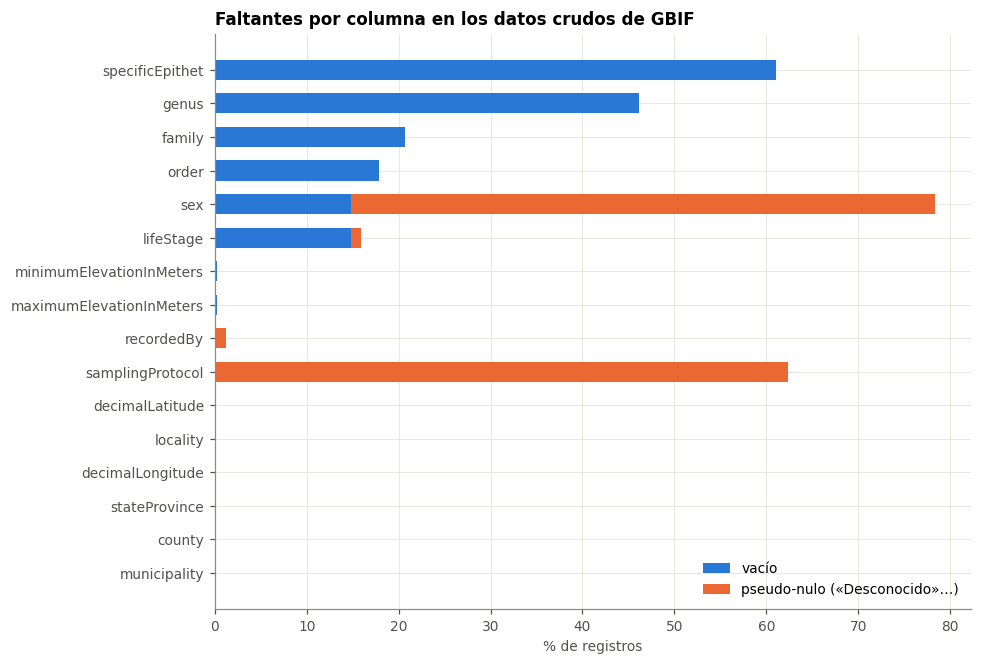

In [8]:
t = faltantes_crudo[(faltantes_crudo["vacíos"] + faltantes_crudo["pseudo_nulos"]) > 0]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(t) + 1))
y = np.arange(len(t))
ax.barh(y, t["% vacíos"], color=AZUL, height=0.6, label="vacío")
ax.barh(y, t["% pseudo_nulos"], left=t["% vacíos"], color=NARANJA, height=0.6, label="pseudo-nulo («Desconocido»…)")
ax.set_yticks(y, t["columna"]); ax.invert_yaxis()
ax.set_xlabel("% de registros"); ax.set_title("Faltantes por columna en los datos crudos de GBIF")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Interpretación.** Los vacíos «reales» son pocos en las columnas de ubicación (coordenadas, elevación),
pero **sexo, etapa de vida y protocolo de muestreo** están dominados por pseudo-nulos: la mayoría de los
especímenes no tiene registrado el sexo ni el protocolo. Las columnas taxonómicas (`order`, `family`, `genus`,
`specificEpithet`) están vacías cuando el especímen no se identificó hasta ese nivel: no es un error de
captura, es el nivel de identificación alcanzado.

### 2.4 Registros duplicados
- **Por identificador:** `id` (= `occurrenceID`, URN del catálogo) debe ser único.
- **Por número de catálogo:** `institutionCode + collectionCode + catalogNumber` identifica al especímen físico.
- **Por contenido:** filas idénticas en todas las columnas excepto los identificadores.

In [9]:
ids_dup = gbif.groupBy("id").count().where("count > 1").count()
cat_dup = gbif.groupBy("institutionCode", "collectionCode", "catalogNumber").count().where("count > 1").count()
sin_ids = [c for c in gbif.columns if c not in ("id", "occurrenceID", "catalogNumber")]
contenido_dup = N_GBIF - gbif.dropDuplicates(sin_ids).count()
print(f"id repetidos:                       {miles(ids_dup)}")
print(f"números de catálogo repetidos:      {miles(cat_dup)}")
print(f"filas con contenido idéntico (salvo identificadores): {miles(contenido_dup)} "
      f"({100 * contenido_dup / N_GBIF:.1f} %)")

id repetidos:                       0
números de catálogo repetidos:      0
filas con contenido idéntico (salvo identificadores): 2 121 721 (64.8 %)


**Interpretación.** No hay identificadores ni números de catálogo repetidos. Las filas con contenido idéntico
salvo el identificador **no son duplicados**: son especímenes distintos del mismo evento de recolecta (por ejemplo,
varios individuos de la misma especie que cayeron en la misma trampa Malaise el mismo mes). Son el 64,8 % de las filas, lo
que muestra que el INBio registra cada especímen individualmente aunque compartan evento. Eliminarlas
subestimaría la abundancia registrada, por lo que se conservan.

### 2.5 Estadísticas descriptivas de las variables numéricas

In [10]:
numericas = gbif.select(
    F.col("decimalLatitude").cast("double").alias("latitud"),
    F.col("decimalLongitude").cast("double").alias("longitud"),
    F.col("minimumElevationInMeters").cast("double").alias("elev_min"),
    F.col("maximumElevationInMeters").cast("double").alias("elev_max"),
    F.col("year").cast("int").alias("anio"), F.col("month").cast("int").alias("mes"),
    F.col("day").cast("int").alias("dia"))
numericas.summary("count", "mean", "stddev", "min", "1%", "25%", "50%", "75%", "99%", "max").toPandas()

,summary,latitud,longitud,elev_min,elev_max,anio,mes,dia
0,count,3276329,3276446,3267610,3267610,3276500,3276500,3276500
1,mean,10.065745369716527,-84.35510093058804,643.0696958939408,677.5823537692687,1995.030320158706,6.010263696017091,8.755537005951473
2,stddev,0.8189298512066578,0.9285100162817277,636.105294948709,642.8612169046185,6.801846728601274,3.264750279038778,9.259749483031872
3,min,5.518488888888889,-87.07972222222222,0.0,0.0,34,1,1
4,1%,8.48017138888889,-85.73101527777777,0.0,10.0,1980,1,1
5,25%,9.632581666666667,-85.37365638888889,100.0,140.0,1991,3,1
6,50%,10.276722777777778,-84.13280611111111,494.0,500.0,1993,6,4
7,75%,10.776783611111112,-83.59128916666667,1100.0,1100.0,1999,9,16
8,99%,11.033855833333334,-82.78379166666667,2600.0,2640.0,2013,12,30
9,max,11.156395388888889,-82.59903247222222,3820.0,3820.0,2015,12,31


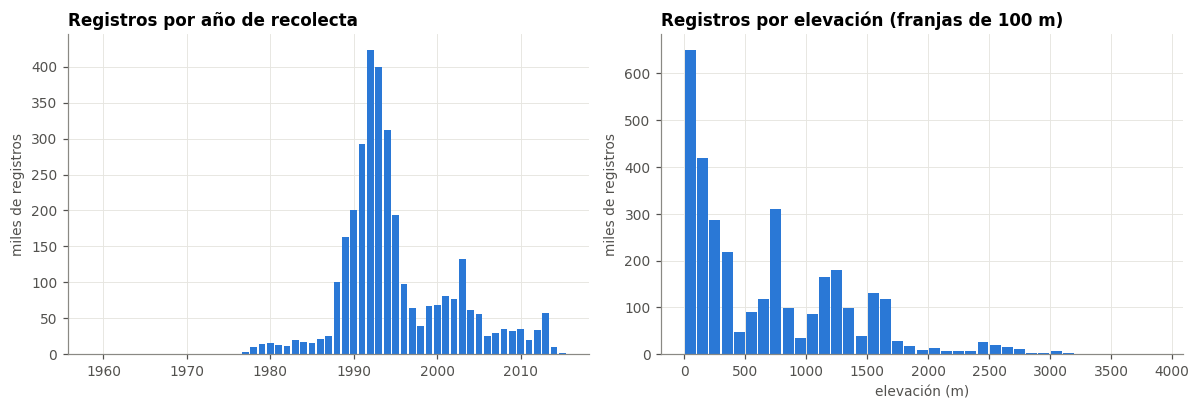

In [11]:
por_anio = (numericas.groupBy("anio").count().where("anio between 1950 and 2020").orderBy("anio").toPandas())
por_elev = (numericas.select(((F.col("elev_min") + F.col("elev_max")) / 2).alias("e"))
            .where("e is not null").groupBy((F.floor(F.col("e") / 100) * 100).alias("franja")).count()
            .orderBy("franja").toPandas())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.bar(por_anio.anio, por_anio["count"] / 1e3, color=AZUL, width=0.8)
a1.set_title("Registros por año de recolecta"); a1.set_ylabel("miles de registros")
a2.bar(por_elev.franja + 50, por_elev["count"] / 1e3, color=AZUL, width=90)
a2.set_title("Registros por elevación (franjas de 100 m)"); a2.set_xlabel("elevación (m)")
a2.set_ylabel("miles de registros"); plt.tight_layout(); plt.show()

**Interpretación.** La actividad de recolecta del INBio se concentra entre finales de los años 80 y mediados de
los 2000 (inventario nacional de biodiversidad), con caída abrupta al final del periodo. La elevación está
sesgada a tierras bajas, coherente con la mayor superficie y accesibilidad de esas zonas, pero hay recolecta
hasta la cima del Chirripó (~3 800 m). En la tabla de estadísticas, el mínimo de `anio` revela años imposibles
(valores atípicos de captura) que se tratan en la limpieza.

### 2.6 Inconsistencias detectadas

In [12]:
inconsist = gbif.agg(
    F.sum(F.when(F.col("eventDate").rlike(r"^\d{4}-\d{2}-\d{2}/\d{4}-\d{2}-\d{2}$"), 1).otherwise(0)).alias("fecha_como_rango"),
    F.sum(F.when(F.col("eventDate").rlike(r"^\d{4}-\d{2}-\d{2}$"), 1).otherwise(0)).alias("fecha_simple"),
    F.sum(F.when(F.substring("eventDate", 1, 4) != F.col("year"), 1).otherwise(0)).alias("anio_distinto_de_fecha"),
    F.sum(F.when(F.col("minimumElevationInMeters").cast("double") != F.col("maximumElevationInMeters").cast("double"), 1).otherwise(0)).alias("elevacion_como_rango"),
    F.sum(F.when(F.col("minimumElevationInMeters").cast("double") > F.col("maximumElevationInMeters").cast("double"), 1).otherwise(0)).alias("elev_min_mayor_que_max"),
    F.sum(F.when(F.length("decimalLatitude") > 12, 1).otherwise(0)).alias("latitud_con_mas_de_10_decimales"),
    F.sum(F.when(F.col("taxonRank") == "Reino", 1).otherwise(0)).alias("identificados_solo_hasta_reino"),
    F.sum(F.when(F.col("stateProvince") == "Indeterminado", 1).otherwise(0)).alias("provincia_indeterminada"),
).toPandas().T.rename(columns={0: "registros"})
inconsist

,registros
fecha_como_rango,3276500
fecha_simple,0
anio_distinto_de_fecha,1
elevacion_como_rango,842744
elev_min_mayor_que_max,0
latitud_con_mas_de_10_decimales,2950142
identificados_solo_hasta_reino,538733
provincia_indeterminada,54


In [13]:
for c in ["taxonRank", "sex", "lifeStage", "samplingProtocol", "stateProvince"]:
    print(f"\n— {c}")
    print(gbif.groupBy(c).count().orderBy(F.desc("count")).limit(12).toPandas().to_string(index=False))


— taxonRank


 taxonRank   count
   Especie 1253072
     Reino  538733
   Familia  488497
    Género  486811
Subfamilia  267020
     Orden   89036
     Tribu   74648
     Clase   46497
Subespecie   22918
  Suborden    3927
 Subgénero    2450
  Subtribu    1229

— sex


          sex   count
  Desconocido 2081850
         None  486296
        Macho  449964
       Hembra  258350
Hembra, Macho      38
    No Aplica       2

— lifeStage
            lifeStage   count
               Adulto 2748817
                 None  486296
          Desconocido   36110
                Ninfa    3253
                Larva    1210
  Hembra reproductiva     644
                 Pupa     118
             Inmaduro      49
Adulto (obrera mayor)       2
          Larva, Pupa       1

— samplingProtocol


        samplingProtocol   count
             Desconocido 2042100
          Trampa Malaise  415862
           Trampa de Luz  256507
                  Manual  231812
            Red de Golpe   61311
                Amarilla   39100
  Trampa de Intersección   38933
Luz de Vapor de Mercurio   32916
      Trampa de Mantillo   21906
          Trampa de Foso   21136
          Red de Barrido   13270
   Cernidor de Hojarasca   12717

— stateProvince
stateProvince   count
   Guanacaste 1000085
   Puntarenas  949908
        Limón  449625
     Alajuela  264426
      Heredia  259291
      Cartago  184207
     San José  168904
Indeterminado      54


In [14]:
print("Nombre científico de los registros identificados solo hasta reino o clase:")
ver(gbif.where(F.col("taxonRank").isin("Reino", "Clase")).groupBy("taxonRank", "scientificName", "order").count())

Nombre científico de los registros identificados solo hasta reino o clase:


,taxonRank,scientificName,order,count
0,Clase,Insecta,None,46497
1,Reino,Animalia,None,538733


### 2.7 Exploración de la capa del SINAC

In [15]:
asp_crudo.createOrReplaceTempView("asp_crudo")
ver(sedona.sql('''
    SELECT codigo, nombre_asp, cat_manejo, siglas_ac, descripcio, CAST(area_km2 AS DOUBLE) AS area_km2,
           ST_GeometryType(geometry) AS tipo_geom, ST_IsValid(geometry) AS valida, ST_NPoints(geometry) AS vertices
    FROM asp_crudo'''), 8)

,codigo,nombre_asp,cat_manejo,siglas_ac,descripcio,area_km2,tipo_geom,valida,vertices
0,A04,Barra del Colorado,Area Marina de Manejo,ACTo,Area Marina de Manejo,651.661831,ST_Polygon,True,1131
1,V01,Barra del Colorado,Refugio Nacional de Vida Silvestre,ACTo,Area terrestre protegida,811.534516,ST_Polygon,True,1901
2,V31,Maquenque,Refugio Nacional de Vida Silvestre,ACAHN,Area terrestre protegida,518.644528,ST_MultiPolygon,True,2355
3,V04,Cano Negro,Refugio Nacional de Vida Silvestre,ACAHN,Area terrestre protegida,101.604231,ST_Polygon,True,347
4,P22,Volcan Tenorio,Parque Nacional,ACAT,Area terrestre protegida,128.978873,ST_Polygon,True,1428
5,V11,Lagunas las Camelias,Refugio Nacional de Vida Silvestre,ACAHN,Area terrestre protegida,0.649988,ST_Polygon,True,7
6,P29,Miravalles-Jorge Manuel Dengo,Parque Nacional,ACAT,Area terrestre protegida,42.327521,ST_Polygon,True,729
7,Z20,Miravalles,Zona Protectora,ACAT,Area terrestre protegida,74.375382,ST_Polygon,True,719


In [16]:
print(sedona.sql('''
    SELECT COUNT(*) AS poligonos, COUNT(DISTINCT codigo) AS codigos, COUNT(DISTINCT nombre_asp) AS nombres,
           SUM(CASE WHEN ST_IsValid(geometry) THEN 0 ELSE 1 END) AS invalidas,
           ROUND(SUM(CAST(area_km2 AS DOUBLE)), 1) AS km2_total
    FROM asp_crudo''').toPandas().to_string(index=False))
print()
print(asp_crudo.groupBy("cat_manejo").agg(F.count("*").alias("áreas"), F.round(F.sum(F.col("area_km2").cast("double")), 1).alias("km2"))
      .orderBy(F.desc("áreas")).toPandas().to_string(index=False))
print()
print(asp_crudo.groupBy("descripcio").count().orderBy(F.desc("count")).toPandas().to_string(index=False))
print("\nNombres repetidos (misma ASP con más de un polígono/categoría):")
print(asp_crudo.groupBy("nombre_asp").agg(F.count("*").alias("n"), F.collect_set("cat_manejo").alias("categorias"))
      .where("n > 1").orderBy(F.desc("n")).toPandas().to_string(index=False))

 poligonos  codigos  nombres  invalidas  km2_total
       173      147      146          0   178048.7



                        cat_manejo  áreas      km2
Refugio Nacional de Vida Silvestre     55   2857.3
                   Parque Nacional     43  62982.2
                   Zona Protectora     33   1513.2
                           Humedal     13    366.1
                 Reserva Biologica     10    328.0
                  Reserva Forestal     10   2152.9
             Area Marina de Manejo      4 107815.6
          Reserva Natural Absoluta      4     31.1
                Monumento Nacional      1      2.3



              descripcio  count
Area terrestre protegida    138
   Area marina protegida     19
                    Isla     11
   Area Marina de Manejo      4
                 Humedal      1

Nombres repetidos (misma ASP con más de un polígono/categoría):


                     nombre_asp  n                                                  categorias
                    Cabo Blanco  4           [Reserva Natural Absoluta, Area Marina de Manejo]
Marino las Baulas de Guanacaste  3                                           [Parque Nacional]
                     Santa Rosa  3                                           [Parque Nacional]
                     Tortuguero  3                          [Parque Nacional, Zona Protectora]
               Bahia Junquillal  2                        [Refugio Nacional de Vida Silvestre]
             Barra del Colorado  2 [Refugio Nacional de Vida Silvestre, Area Marina de Manejo]
                        Cahuita  2                                           [Parque Nacional]
                   Caletas Ario  2                        [Refugio Nacional de Vida Silvestre]
                      Camaronal  2                        [Refugio Nacional de Vida Silvestre]
                      Corcovado  2                

**¿`codigo` identifica a un polígono?** No necesariamente: una misma ASP puede estar formada por varios polígonos
(parte terrestre, marina, isla) que comparten código, y además puede haber códigos reutilizados por error.

In [17]:
rep_cod = (asp_crudo.groupBy("codigo").agg(F.count("*").alias("poligonos"), F.collect_set("nombre_asp").alias("nombres"),
                                            F.collect_list("descripcio").alias("tipos"))
           .where("poligonos > 1").orderBy(F.desc("poligonos")))
print("Códigos con más de un polígono:", rep_cod.count())
print("Códigos usados por ASP con nombres distintos:", rep_cod.where(F.size("nombres") > 1).count())
ver(rep_cod, 30)

Códigos con más de un polígono: 23


Códigos usados por ASP con nombres distintos: 3


,codigo,poligonos,nombres,tipos
0,N01,3,[Cabo Blanco],"[Isla, Area terrestre protegida, Area marina protegida]"
1,P07,3,[Marino las Baulas de Guanacaste],"[Isla, Area terrestre protegida, Area marina protegida]"
2,P10,3,[Santa Rosa],"[Area terrestre protegida, Isla, Area marina protegida]"
3,B02,2,[Isla del Cano],"[Isla, Area marina protegida]"
4,H07,2,[Marino Playa Blanca],"[Area terrestre protegida, Area marina protegida]"
5,P11,2,[Tortuguero],"[Area marina protegida, Area terrestre protegida]"
6,P12,2,[Corcovado],"[Area terrestre protegida, Area marina protegida]"
7,P13,2,[Piedras Blancas],"[Area terrestre protegida, Area marina protegida]"
8,P14,2,[Marino Ballena],"[Area terrestre protegida, Area marina protegida]"
9,P15,2,[Manuel Antonio],"[Area terrestre protegida, Area marina protegida]"


**Validación cruzada capa (2023) ↔ registro oficial (2025).** Ambas fuentes del SINAC deberían describir las
mismas áreas. Primero se prueba el código; como se verá, **los códigos se reasignaron entre versiones**, así que la
comparación válida es por nombre normalizado + categoría de manejo.

**Resultado:** de los códigos presentes en ambas fuentes, la gran mayoría designa *otra* ASP en el registro 2025
(el código no es una clave estable entre versiones). Por nombre + categoría, 148 de 149 ASP de la capa están en
el registro; las diferencias son cambios reales de la normativa: «Río Pacuare» pasó de Reserva Forestal a Zona
Protectora y en 2025 se creó el «Monumento Natural Zona de Los Santos», que todavía no tiene polígono en la capa.
Se usa la capa 2023 porque es la única fuente con geometría; la diferencia afecta a 2 de 150 áreas.

In [18]:
capa_u = asp_crudo.select("codigo", "nombre_asp", "cat_manejo").distinct()
mismo_cod = capa_u.alias("c").join(registro.alias("r"), "codigo")
print("Códigos presentes en ambas fuentes:", mismo_cod.count(),
      "| de ellos con otro nombre en el registro:", mismo_cod.where("lower(c.nombre_asp) <> lower(r.nombre_asp)").count())
ver(mismo_cod.where("lower(c.nombre_asp) <> lower(r.nombre_asp)")
    .select("codigo", F.col("c.nombre_asp").alias("nombre_capa_2023"), F.col("r.nombre_asp").alias("nombre_registro_2025")), 5)

clave = lambda df: df.select(F.lower(F.trim("nombre_asp")).alias("nombre"), F.lower(F.trim("cat_manejo")).alias("categoria")).distinct()
k_capa, k_reg = clave(asp_crudo), clave(registro)
print("ASP (nombre+categoría) en la capa:", k_capa.count(), "| en el registro:", k_reg.count(),
      "| en ambos:", k_capa.join(k_reg, ["nombre", "categoria"]).count())
print("Solo en la capa 2023:"); display(k_capa.join(k_reg, ["nombre", "categoria"], "left_anti").toPandas())
print("Solo en el registro 2025:"); display(k_reg.join(k_capa, ["nombre", "categoria"], "left_anti").toPandas())

Códigos presentes en ambas fuentes: 178 | de ellos con otro nombre en el registro: 141


ASP (nombre+categoría) en la capa: 149 | en el registro: 150 | en ambos: 148
Solo en la capa 2023:


,nombre,categoria
0,rio pacuare,reserva forestal


Solo en el registro 2025:


,nombre,categoria
0,monumento natural zona de los santos,monumento natural
1,rio pacuare,zona protectora


### 2.8 Resumen del estado inicial de los datos

| Problema | Dónde | Tratamiento |
|---|---|---|
| Columnas constantes, vacías o fuera del tema | GBIF (15 constantes/vacías de 55) | Se seleccionan 25 columnas relevantes |
| Todo leído como texto; números con hasta 40 decimales | coordenadas, elevación, año/mes/día | Conversión de tipos y redondeo (§3.4) |
| Fecha como rango `inicio/fin` | `eventDate` (todas las filas) | Separar inicio/fin; variable derivada de precisión (§3.4) |
| Años imposibles (0034 y 1010) | `eventDate`, `year` (2 filas) | Rango válido 1900–fecha de publicación (§3.4) |
| Elevación como rango min/max | 842 744 filas (26 %) | Punto medio + variable derivada de amplitud (§3.5) |
| Epítetos que no son especies (morfoespecies «sp12», «cf.», «?») | `specificEpithet` | `especie` solo con epíteto binomial válido (§3.3) |
| Pseudo-nulos «Desconocido»/«Indeterminado» | sexo, etapa, protocolo, provincia | Se convierten a nulo y se imputan (§3, §4) |
| Identificaciones solo hasta reino/clase | 585 230 registros (17,9 %) | Se conservan con orden/familia «No determinado» |
| Coordenadas faltantes | 175 filas (ninguna fuera de Costa Rica) | Validación (§3.6) y eliminación (§4) |
| Nombres sin tildes, mayúsculas inconsistentes | SINAC (43 nombres) | Estandarización de textos (§6.1) |
| `codigo` no es único: 23 códigos con varios polígonos, 2 reutilizados por ASP distintas; códigos reasignados entre 2023 y 2025 | SINAC | Identificador propio `id_poligono` para el join (§6.1); cruce de versiones por nombre + categoría |
| ASP solapadas (misma zona en dos categorías) | SINAC | Regla de asignación única (§6.3) |

## 3. Limpieza y transformación

Cada paso indica **problema → transformación → efecto**. La cantidad de registros se registra en una bitácora
después de cada paso que puede cambiarla.

In [19]:
bitacora = []
def registrar(paso, df):
    n = df.count()
    bitacora.append({"paso": paso, "registros": n})
    print(f"{paso}: {miles(n)}")
    return n

registrar("0. Datos crudos GBIF", gbif)

0. Datos crudos GBIF: 3 276 500


3276500

### 3.1 Selección y renombrado de columnas
**Problema:** 55 columnas en inglés (Darwin Core), la mayoría sin variación. **Transformación:** se conservan las
25 relevantes con nombres en español. **Efecto:** el dataset de trabajo es más liviano y legible; no cambia el
número de filas.

In [20]:
occ = gbif.select(
    F.col("id"), F.col("catalogNumber").alias("numero_catalogo"),
    F.col("scientificName").alias("nombre_cientifico"), F.col("taxonRank").alias("rango_taxonomico"),
    F.col("order").alias("orden"), F.col("family").alias("familia"), F.col("genus").alias("genero"),
    F.col("specificEpithet").alias("epiteto"),
    F.col("eventDate").alias("fecha_cruda"), F.col("year").alias("anio_crudo"),
    F.col("stateProvince").alias("provincia"), F.col("county").alias("canton"),
    F.col("municipality").alias("distrito"), F.col("locality").alias("localidad"),
    F.col("minimumElevationInMeters").alias("elev_min"), F.col("maximumElevationInMeters").alias("elev_max"),
    F.col("decimalLatitude").alias("lat_cruda"), F.col("decimalLongitude").alias("lon_cruda"),
    F.col("geodeticDatum").alias("datum"),
    F.col("sex").alias("sexo"), F.col("lifeStage").alias("etapa_vida"),
    F.col("samplingProtocol").alias("protocolo_muestreo"), F.col("recordedBy").alias("recolector"))
print(occ.columns)

['id', 'numero_catalogo', 'nombre_cientifico', 'rango_taxonomico', 'orden', 'familia', 'genero', 'epiteto', 'fecha_cruda', 'anio_crudo', 'provincia', 'canton', 'distrito', 'localidad', 'elev_min', 'elev_max', 'lat_cruda', 'lon_cruda', 'datum', 'sexo', 'etapa_vida', 'protocolo_muestreo', 'recolector']


### 3.2 Duplicados
**Problema:** el enunciado exige verificar que no existan duplicados. **Transformación:** `dropDuplicates(["id"])`.
**Efecto:** según §2.4 no hay ids repetidos, por lo que el conteo no cambia; el paso deja la garantía explícita.

In [21]:
occ = occ.dropDuplicates(["id"])
registrar("1. Sin duplicados por id", occ)

1. Sin duplicados por id: 3 276 500


3276500

### 3.3 Estandarización de textos
**Problema:** espacios sobrantes, pseudo-nulos y variantes de una misma categoría
(«Hembra reproductiva», «Adulto (obrera mayor)» son adultos; «Hembra, Macho» es un lote con ambos sexos).
**Transformación:**
1. `trim` y colapso de espacios múltiples en todos los textos.
2. Pseudo-nulos (`Desconocido`, `Indeterminado`, `No Aplica`, vacío) → `null`, para que el tratamiento de
   faltantes los vea como lo que son.
3. Normalización de categorías de etapa de vida y sexo con un diccionario explícito.
4. Taxonomía: orden y familia vacíos → **«No determinado»** (especímenes identificados solo hasta reino o clase;
   decisión: se conservan porque tienen ubicación válida y representan esfuerzo de muestreo).
5. `especie` (nombre binomial *Género epíteto*) solo se construye cuando el epíteto es un epíteto real: una
   palabra en minúsculas sin dígitos ni signos. El campo `specificEpithet` del INBio también contiene
   **morfoespecies** («sp», «sp.12», «sp145», «CR-8»), **identificaciones dudosas** («cf.», «aff.», «nr.»,
   «memor?») y **subespecies** («occidentalis bohemani»). Las dos primeras no son especies identificadas y
   contarlas inflaría los rankings y la riqueza de especies; de las subespecies se toma solo la especie.
   `nombre_cientifico` conserva el valor original.

**Efecto:** categorías consistentes para facets en Solr; los faltantes quedan explícitos.

In [22]:
TEXTOS = ["nombre_cientifico", "rango_taxonomico", "orden", "familia", "genero", "epiteto", "provincia", "canton",
          "distrito", "localidad", "datum", "sexo", "etapa_vida", "protocolo_muestreo", "recolector"]

def limpiar_texto(c):
    t = F.regexp_replace(F.trim(F.col(c)), r"\s+", " ")
    return F.when(t.isNull() | (t == "") | F.lower(t).isin(PSEUDO_NULOS), F.lit(None)).otherwise(t)

for c in TEXTOS:
    occ = occ.withColumn(c, limpiar_texto(c))

ETAPAS = {"Adulto": "Adulto", "Hembra reproductiva": "Adulto", "Adulto (obrera mayor)": "Adulto",
          "Larva": "Larva", "Larva, Pupa": "Larva", "Pupa": "Pupa", "Ninfa": "Ninfa", "Inmaduro": "Inmaduro"}
SEXOS = {"Macho": "Macho", "Hembra": "Hembra", "Hembra, Macho": "Mixto"}
MARCADORES = ["sp", "spp", "cf", "aff", "nr", "nsp", "near", "group", "grupo", "complex", "complejo", "indet"]

def mapear(c, dic):
    m = F.create_map(*[F.lit(x) for kv in dic.items() for x in kv])
    return F.when(F.col(c).isNull(), None).otherwise(F.coalesce(m[F.col(c)], F.col(c)))

occ = (occ
       .withColumn("etapa_vida", mapear("etapa_vida", ETAPAS))
       .withColumn("sexo", mapear("sexo", SEXOS))
       .withColumn("orden", F.coalesce("orden", F.lit("No determinado")))
       .withColumn("familia", F.coalesce("familia", F.lit("No determinado")))
       .withColumn("_ep", F.split("epiteto", " ").getItem(0))
       .withColumn("epiteto_valido", F.col("_ep").rlike("^[a-z]{2,}$") & ~F.col("_ep").isin(MARCADORES))
       .withColumn("especie", F.when(F.col("genero").isNotNull() & F.col("epiteto_valido"),
                                     F.concat_ws(" ", "genero", "_ep")))
       .drop("_ep"))

print("Epítetos que NO forman una especie (morfoespecies, dudosos), ejemplos:")
display(occ.where(F.col("epiteto").isNotNull() & ~F.col("epiteto_valido")).groupBy("epiteto").count()
        .orderBy(F.desc("count")).limit(15).toPandas().T)
print("Registros con epíteto:", miles(occ.where(F.col("epiteto").isNotNull()).count()),
      "| con especie válida:", miles(occ.where(F.col("especie").isNotNull()).count()),
      "| subespecies reducidas a especie:", miles(occ.where(F.col("epiteto_valido") & F.col("epiteto").contains(" ")).count()))

for c in ["etapa_vida", "sexo", "orden"]:
    print(occ.groupBy(c).count().orderBy(F.desc("count")).limit(12).toPandas().to_string(index=False), "\n")

Epítetos que NO forman una especie (morfoespecies, dudosos), ejemplos:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
epiteto,sp,sp.,sp.1,sp1,spp.,sp3,sp.2,sp.3,sp. 1,sp2,sp6,sp145,sp5,sp.12,#1
count,129629,26878,6610,4317,2690,2248,2215,1786,1519,1420,1314,1038,1027,1009,923


Registros con epíteto: 1 276 475 | con especie válida: 1 040 647 | subespecies reducidas a especie: 9 588


etapa_vida   count
    Adulto 2749463
      None  522406
     Ninfa    3253
     Larva    1211
      Pupa     118
  Inmaduro      49 



  sexo   count
  None 2568148
 Macho  449964
Hembra  258350
 Mixto      38 



         orden  count
    Coleoptera 895524
   Lepidoptera 618981
No determinado 585230
       Diptera 475729
   Hymenoptera 472586
     Hemiptera 186098
    Orthoptera  22579
    Neuroptera   5119
       Odonata   3841
   Trichoptera   3220
      Mantodea   2129
 Ephemeroptera   2067 



### 3.4 Fechas
**Problema:** `eventDate` siempre viene como rango `AAAA-MM-DD/AAAA-MM-DD` (el INBio registra el periodo en que
estuvo activa la trampa) y hay años imposibles (0034, 1010) por errores de digitación.
**Transformación:** se separa el rango en `fecha_inicio` y `fecha_fin` (`to_date`); si el fin es anterior al
inicio se intercambian. La **fecha del evento** es la de inicio (convención: el evento comenzó ese día; usar el
punto medio podría mover registros de mes). Una fecha es válida si está entre 1900-01-01 y la fecha de
publicación del dataset (`modified` máximo); las demás se anulan y se cuentan. `anio` y `mes` se derivan de
la fecha validada.
**Efecto:** fecha en formato ISO lista para el tipo `pdate` de Solr; años fuera de rango eliminados del análisis
temporal (no se elimina el registro, solo la fecha inválida).

In [23]:
FECHA_MAX = gbif.agg(F.max(F.to_date("modified"))).first()[0]
print("Fecha de publicación (máximo de 'modified'):", FECHA_MAX)

partes = F.split("fecha_cruda", "/")
occ = (occ.withColumn("_ini", F.to_date(partes.getItem(0)))
          .withColumn("_fin", F.coalesce(F.to_date(partes.getItem(1)), F.col("_ini")))
          .withColumn("fecha_inicio", F.least("_ini", "_fin"))
          .withColumn("fecha_fin", F.greatest("_ini", "_fin")))
valida = F.col("fecha_inicio").between(F.lit("1900-01-01").cast("date"), F.lit(FECHA_MAX))
fechas_invalidas = occ.where(F.col("fecha_inicio").isNotNull() & ~valida)
print(f"Fechas fuera de rango: {fechas_invalidas.count()}")
print(fechas_invalidas.groupBy("fecha_cruda").count().toPandas().to_string(index=False))

occ = (occ.withColumn("fecha_inicio", F.when(valida, F.col("fecha_inicio")))
          .withColumn("fecha_fin", F.when(valida, F.col("fecha_fin")))
          .withColumn("fecha_evento", F.col("fecha_inicio"))
          .withColumn("anio", F.year("fecha_evento"))
          .withColumn("mes", F.month("fecha_evento"))
          .drop("_ini", "_fin"))
print("Año declarado ≠ año de la fecha:",
      occ.where(F.col("anio").isNotNull() & (F.col("anio_crudo").cast("int") != F.col("anio"))).count())

Fecha de publicación (máximo de 'modified'): 2015-11-13


Fechas fuera de rango: 2


          fecha_cruda  count
1010-12-08/1010-12-08      1
0034-02-18/0034-02-28      1


Año declarado ≠ año de la fecha: 0


### 3.5 Valores numéricos: coordenadas y elevación
**Problema:** coordenadas con hasta 40 decimales (precisión ficticia: 6 decimales ≈ 0,1 m); la elevación viene
como rango mínimo–máximo.
**Transformación:** conversión a `double`; coordenadas redondeadas a 6 decimales. Si `elev_min > elev_max` se
intercambian; `elevacion_m` es el **punto medio** del rango (o el único valor presente).
**Efecto:** tipos numéricos correctos (`pdouble` en Solr) y una sola elevación por registro.

In [24]:
occ = (occ.withColumn("latitud", F.round(F.col("lat_cruda").cast("double"), 6))
          .withColumn("longitud", F.round(F.col("lon_cruda").cast("double"), 6))
          .withColumn("_emin", F.col("elev_min").cast("double"))
          .withColumn("_emax", F.col("elev_max").cast("double"))
          .withColumn("elev_min", F.least("_emin", "_emax"))
          .withColumn("elev_max", F.greatest("_emin", "_emax"))
          .withColumn("elevacion_m", (F.col("elev_min") + F.col("elev_max")) / 2)
          .drop("_emin", "_emax"))
occ.select("latitud", "longitud", "elev_min", "elev_max", "elevacion_m").summary("min", "50%", "max").toPandas()

,summary,latitud,longitud,elev_min,elev_max,elevacion_m
0,min,5.518489,-87.079722,0.0,0.0,0.0
1,50%,10.276723,-84.132806,494.0,500.0,500.0
2,max,11.156395,-82.599032,3820.0,3820.0,3820.0


### 3.6 Datos atípicos o fuera de rango
Se revisan tres columnas con reglas de dominio (rangos físicamente posibles), distintas de la detección
estadística de anomalías de la sección 5:

| Columna | Rango válido | Justificación |
|---|---|---|
| `fecha_evento` | 1900-01-01 … fecha de publicación | No puede haber recolectas futuras ni de hace siglos (ya aplicado en §3.4) |
| `elevacion_m` | 0 … 3 821 m | Del nivel del mar a la cima del Chirripó, punto más alto del país |
| `latitud`, `longitud` | Costa Rica continental (7,9…11,3 N; 86,0…82,5 O) o Isla del Coco (5,4…5,6 N; 87,2…86,9 O) | El dataset es *Insecta of Costa Rica* |

**Transformación:** los valores fuera de rango se anulan (no se inventan) y se cuentan. Para las coordenadas se
prueba además si están **invertidas** (lat↔lon), error frecuente de digitación; si al intercambiarlas caen en
Costa Rica, se corrigen.

In [25]:
def en_costa_rica(lat, lon):
    return (lat.between(7.9, 11.3) & lon.between(-86.0, -82.5)) | (lat.between(5.4, 5.6) & lon.between(-87.2, -86.9))

lat, lon = F.col("latitud"), F.col("longitud")
diag = occ.agg(
    F.sum(F.when(lat.isNull() | lon.isNull(), 1).otherwise(0)).alias("sin_coordenadas"),
    F.sum(F.when((lat == 0) & (lon == 0), 1).otherwise(0)).alias("coordenadas_0_0"),
    F.sum(F.when(lat.isNotNull() & ~en_costa_rica(lat, lon), 1).otherwise(0)).alias("fuera_de_costa_rica"),
    F.sum(F.when(lat.isNotNull() & ~en_costa_rica(lat, lon) & en_costa_rica(lon, lat), 1).otherwise(0)).alias("invertidas_corregibles"),
    F.sum(F.when(F.col("elevacion_m") < 0, 1).otherwise(0)).alias("elevacion_negativa"),
    F.sum(F.when(F.col("elevacion_m") > 3821, 1).otherwise(0)).alias("elevacion_mayor_3821"),
    F.sum(F.when(F.col("datum") != "WGS84", 1).otherwise(0)).alias("datum_distinto_WGS84"),
).toPandas().T.rename(columns={0: "registros"})
display(diag)
ver(occ.where(lat.isNotNull() & ~en_costa_rica(lat, lon)).select("id", "lat_cruda", "lon_cruda", "provincia", "localidad"))

,registros
sin_coordenadas,175
coordenadas_0_0,0
fuera_de_costa_rica,0
invertidas_corregibles,0
elevacion_negativa,0
elevacion_mayor_3821,0
datum_distinto_WGS84,0


,id,lat_cruda,lon_cruda,provincia,localidad


In [26]:
invertida = lat.isNotNull() & ~en_costa_rica(lat, lon) & en_costa_rica(lon, lat)
occ = (occ.withColumn("_lat", F.when(invertida, lon).otherwise(lat))
          .withColumn("_lon", F.when(invertida, lat).otherwise(lon))
          .withColumn("coordenada_valida", F.col("_lat").isNotNull() & en_costa_rica(F.col("_lat"), F.col("_lon")))
          .withColumn("latitud", F.when(F.col("coordenada_valida"), F.col("_lat")))
          .withColumn("longitud", F.when(F.col("coordenada_valida"), F.col("_lon")))
          .withColumn("elevacion_m", F.when(F.col("elevacion_m").between(0, 3821), F.col("elevacion_m")))
          .drop("_lat", "_lon"))
print("Coordenadas no válidas (quedan en null):", occ.where(~F.col("coordenada_valida")).count())

Coordenadas no válidas (quedan en null): 171


### 3.7 Variables derivadas
Se crean cuatro variables calculadas a partir de los datos existentes:

| Variable | Cálculo | Utilidad |
|---|---|---|
| `estacion` | `Seca` si el mes es dic–abr, si no `Lluviosa` | Estacionalidad climática del Pacífico/Valle Central de Costa Rica; facet en Solr |
| `precision_temporal_dias` | `fecha_fin − fecha_inicio + 1` | Cuánto duró el evento de muestreo (trampa activa) |
| `amplitud_elevacion_m` | `elev_max − elev_min` | Incertidumbre de la elevación reportada |
| `piso_altitudinal` | Basal <500 m, Premontano <1500, Montano bajo <2500, Montano ≥2500 | Zonas de vida altitudinales (Holdridge simplificado). Se calcula en §4, **después** de imputar la elevación |

Además, en la integración (§6) se deriva `distancia_borde_m`: la distancia del registro al límite de su ASP.

In [27]:
occ = (occ.withColumn("estacion", F.when(F.col("mes").isin(12, 1, 2, 3, 4), "Seca")
                                   .when(F.col("mes").isNotNull(), "Lluviosa"))
          .withColumn("precision_temporal_dias", F.datediff("fecha_fin", "fecha_inicio") + 1)
          .withColumn("amplitud_elevacion_m", F.col("elev_max") - F.col("elev_min")))
occ.select("precision_temporal_dias", "amplitud_elevacion_m").summary("min", "25%", "50%", "75%", "max").toPandas()

,summary,precision_temporal_dias,amplitud_elevacion_m
0,min,1,0.0
1,25%,5,0.0
2,50%,25,0.0
3,75%,31,10.0
4,max,3654,3000.0


In [28]:
occ.write.mode("overwrite").parquet(f"{TRABAJO}/occ_limpio.parquet")
occ = spark.read.parquet(f"{TRABAJO}/occ_limpio.parquet")
registrar("2. Limpio (antes de tratar faltantes)", occ)

2. Limpio (antes de tratar faltantes): 3 276 500


3276500

## 4. Tratamiento e imputación de datos faltantes

### 4.1 Diagnóstico después de la limpieza
Con los pseudo-nulos ya convertidos a `null`, el perfil de faltantes refleja la ausencia real de información.

In [29]:
COLS_ANALISIS = ["latitud", "longitud", "elevacion_m", "fecha_evento", "anio", "provincia", "canton", "localidad",
                 "sexo", "etapa_vida", "protocolo_muestreo", "recolector", "genero", "especie"]
faltantes_limpio = perfil_faltantes(occ, COLS_ANALISIS)[["columna", "vacíos", "% vacíos"]]
faltantes_limpio

,columna,vacíos,% vacíos
0,sexo,2568148,78.38
1,especie,2235853,68.24
2,protocolo_muestreo,2042324,62.33
3,genero,1510764,46.11
4,etapa_vida,522406,15.94
5,recolector,38787,1.18
6,elevacion_m,8890,0.27
7,latitud,175,0.01
8,longitud,175,0.01
9,localidad,78,0.00


### 4.2 ¿Eliminar o imputar?

| Variable | Decisión | Justificación |
|---|---|---|
| `latitud`/`longitud` | **Eliminar** el registro | La ubicación es el eje del proyecto (join espacial, consultas geográficas). Una coordenada no puede inferirse con precisión desde el texto de localidad; son muy pocos registros. |
| `elevacion_m` | **Imputar: mediana espacial jerárquica** | Numérica, fuertemente dependiente de la ubicación; los vecinos cercanos tienen elevaciones parecidas. |
| `etapa_vida` | **Imputar: moda por orden** | Categórica muy desbalanceada; la etapa típica depende del grupo taxonómico. |
| `provincia`, `canton` | **Imputar: moda espacial** (valor más frecuente en la celda de 1 km, o de 5 km) | Los mismos registros carecen de provincia y cantón a la vez; los vecinos inmediatos con división administrativa conocida indican en cuál están. |
| `sexo` | **Constante «Indeterminado»** | Imputar la moda inventaría machos/hembras y sesgaría cualquier proporción de sexos; se marca explícitamente como no determinado. |
| `protocolo_muestreo`, `recolector` | **Constante «No registrado»** | Dato administrativo; no hay base para inferirlo. |
| `fecha_evento`, `anio`, `mes` | **Se dejan nulos** | Muy pocos casos (fechas imposibles); el resto del registro es válido. En Solr el campo queda ausente. |
| `genero`, `especie` | **No se imputan** | Reflejan el nivel de identificación alcanzado (incluidas las morfoespecies), no un dato perdido. |

In [30]:
occ = occ.where(F.col("coordenada_valida"))
registrar("3. Sin registros con coordenadas faltantes o inválidas", occ)

3. Sin registros con coordenadas faltantes o inválidas: 3 276 325


3276325

### 4.3 Elevación — mediana espacial jerárquica
Para cada registro sin elevación se usa la **mediana de la elevación de los registros cercanos**, en tres niveles:
1. celda de 0,01° (≈1,1 km) que contiene al punto;
2. si la celda no tiene datos, celda de 0,05° (≈5,5 km);
3. si tampoco, la mediana del cantón.

La mediana (y no la media) es robusta a los valores extremos de laderas. Se compara contra la alternativa
estándar de Spark ML (`Imputer`, mediana global) con una **prueba de retención**: se ocultan las elevaciones del
5 % de los registros que sí la tienen, se imputan con ambos métodos usando solo el 95 % restante y se mide el
error absoluto medio (MAE).

In [31]:
from pyspark.ml.feature import Imputer

def con_celdas(df):
    return (df.withColumn("celda_1km", F.concat_ws("_", F.floor(F.col("latitud") / 0.01), F.floor(F.col("longitud") / 0.01)))
              .withColumn("celda_5km", F.concat_ws("_", F.floor(F.col("latitud") / 0.05), F.floor(F.col("longitud") / 0.05))))

def medianas(df_ref):
    "Tablas de medianas por celda 1 km, celda 5 km y cantón, calculadas con los registros que sí tienen elevación."
    ref = df_ref.where(F.col("elevacion_m").isNotNull())
    m1 = ref.groupBy("celda_1km").agg(F.percentile_approx("elevacion_m", 0.5).alias("med_1km"))
    m5 = ref.groupBy("celda_5km").agg(F.percentile_approx("elevacion_m", 0.5).alias("med_5km"))
    mc = ref.groupBy("canton").agg(F.percentile_approx("elevacion_m", 0.5).alias("med_canton"))
    return m1, m5, mc

def imputar_elevacion(df, m1, m5, mc, col="elevacion_m"):
    df = df.join(m1, "celda_1km", "left").join(m5, "celda_5km", "left").join(mc, "canton", "left")
    fuente = (F.when(F.col(col).isNotNull(), "original").when(F.col("med_1km").isNotNull(), "mediana celda 1 km")
               .when(F.col("med_5km").isNotNull(), "mediana celda 5 km")
               .when(F.col("med_canton").isNotNull(), "mediana del cantón").otherwise("sin dato"))
    return (df.withColumn("fuente_elevacion", fuente)
              .withColumn(col, F.coalesce(col, "med_1km", "med_5km", "med_canton"))
              .drop("med_1km", "med_5km", "med_canton"))

occ = con_celdas(occ)

# --- Prueba de retención ---
conocidos = occ.where(F.col("elevacion_m").isNotNull()).select("id", "celda_1km", "celda_5km", "canton", "elevacion_m")
entren, prueba = conocidos.randomSplit([0.95, 0.05], seed=SEMILLA)
prueba = prueba.withColumnRenamed("elevacion_m", "real").withColumn("elevacion_m", F.lit(None).cast("double"))
m1, m5, mc = medianas(entren)
pred_espacial = imputar_elevacion(prueba, m1, m5, mc)
imputer = Imputer(strategy="median", inputCols=["elevacion_m"], outputCols=["elev_global"]).fit(entren)
mediana_global = imputer.surrogateDF.first()[0]
eval_ = pred_espacial.agg(
    F.count("*").alias("registros_prueba"),
    F.round(F.avg(F.abs(F.col("elevacion_m") - F.col("real"))), 1).alias("MAE_mediana_espacial_m"),
    F.round(F.avg(F.abs(F.lit(mediana_global) - F.col("real"))), 1).alias("MAE_mediana_global_m")).toPandas()
print("Mediana global (Spark ML Imputer):", mediana_global)
display(eval_)
display(pred_espacial.groupBy("fuente_elevacion").count().toPandas())

Mediana global (Spark ML Imputer): 500.0


,registros_prueba,MAE_mediana_espacial_m,MAE_mediana_global_m
0,163756,11.9,513.0


,fuente_elevacion,count
0,mediana celda 5 km,13
1,mediana celda 1 km,163741
2,mediana del cantón,2


In [32]:
# --- Imputación real con todos los registros conocidos ---
m1, m5, mc = medianas(occ)
occ = imputar_elevacion(occ, m1, m5, mc)
display(occ.groupBy("fuente_elevacion").count().orderBy(F.desc("count")).toPandas())

,fuente_elevacion,count
0,original,3267435
1,mediana celda 1 km,8827
2,mediana celda 5 km,51
3,mediana del cantón,12


**Interpretación.** En la prueba de retención (≈164 000 elevaciones ocultas) la mediana espacial tiene un error
absoluto medio de **≈12 m**, frente a **≈513 m** de la mediana global de Spark ML (500 m). En un país con gradientes
de 0 a 3 800 m, asignar una elevación «nacional» a un punto de tierras bajas o de páramo sería un error de cientos
o miles de metros. De los 8 890 faltantes reales, 8 827 se resolvieron con el vecindario de 1 km, 51 con el de
5 km y 12 con la mediana del cantón.

### 4.4 Etapa de vida — moda por orden taxonómico
Se calcula la etapa más frecuente de cada orden con una ventana de Spark (`row_number` sobre los conteos) y se
usa para completar los nulos de ese orden; si un orden no tuviera ningún valor conocido se usa la moda global.

In [33]:
conteo = occ.where(F.col("etapa_vida").isNotNull()).groupBy("orden", "etapa_vida").count()
w = Window.partitionBy("orden").orderBy(F.desc("count"), "etapa_vida")
moda_orden = (conteo.withColumn("r", F.row_number().over(w)).where("r = 1")
              .select("orden", F.col("etapa_vida").alias("moda_etapa"), F.col("count").alias("n_moda")))
moda_global = conteo.groupBy("etapa_vida").agg(F.sum("count").alias("n")).orderBy(F.desc("n")).first()[0]
print("Moda global:", moda_global)
display(moda_orden.orderBy(F.desc("n_moda")).toPandas())

antes = occ.where(F.col("etapa_vida").isNull()).count()
occ = (occ.join(F.broadcast(moda_orden.select("orden", "moda_etapa")), "orden", "left")
          .withColumn("etapa_vida_imputada", F.col("etapa_vida").isNull())
          .withColumn("etapa_vida", F.coalesce("etapa_vida", "moda_etapa", F.lit(moda_global)))
          .drop("moda_etapa"))
print(f"Etapas de vida imputadas: {miles(antes)}")

Moda global: Adulto


,orden,moda_etapa,n_moda
0,Coleoptera,Adulto,892121
1,Lepidoptera,Adulto,617160
2,Diptera,Adulto,474373
3,Hymenoptera,Adulto,470137
4,Hemiptera,Adulto,182413
5,No determinado,Adulto,74137
6,Orthoptera,Adulto,20846
7,Neuroptera,Adulto,4957
8,Odonata,Adulto,3511
9,Trichoptera,Adulto,2850


Etapas de vida imputadas: 522 379


**Interpretación.** La moda es «Adulto» en todos los órdenes (más del 98 % de los valores conocidos), coherente con
los métodos de recolecta del INBio (trampas Malaise y de luz capturan adultos). Se imputaron 522 379 valores.

### 4.5 Provincia y cantón — moda espacial; sexo, protocolo y recolector — valor constante
Provincia y cantón son categóricas y espaciales: se toma el valor más frecuente entre los registros de la misma
celda de 1 km (o 5 km si la celda no tiene ninguno). Se imputan juntas desde la misma celda para que el par
provincia–cantón sea coherente.

In [34]:
def moda_admin(celda):
    "Par (provincia, cantón) más frecuente en cada celda."
    c = occ.where(F.col("provincia").isNotNull() & F.col("canton").isNotNull()).groupBy(celda, "provincia", "canton").count()
    w = Window.partitionBy(celda).orderBy(F.desc("count"), "provincia", "canton")
    return (c.withColumn("r", F.row_number().over(w)).where("r = 1")
             .select(celda, F.col("provincia").alias(f"prov_{celda}"), F.col("canton").alias(f"cant_{celda}")))

antes = occ.where(F.col("provincia").isNull() | F.col("canton").isNull()).count()
occ = (occ.join(moda_admin("celda_1km"), "celda_1km", "left").join(moda_admin("celda_5km"), "celda_5km", "left")
          .withColumn("admin_imputada", F.col("provincia").isNull())
          .withColumn("provincia", F.coalesce("provincia", "prov_celda_1km", "prov_celda_5km"))
          .withColumn("canton", F.when(F.col("admin_imputada"), F.coalesce("cant_celda_1km", "cant_celda_5km")).otherwise(F.col("canton")))
          .drop("prov_celda_1km", "cant_celda_1km", "prov_celda_5km", "cant_celda_5km"))
despues = occ.where(F.col("provincia").isNull() | F.col("canton").isNull()).count()
print(f"Registros sin provincia/cantón: {antes} → {despues}")
display(occ.where("admin_imputada").groupBy("provincia", "canton").count().orderBy(F.desc("count")).toPandas())

occ = (occ.withColumn("sexo", F.coalesce("sexo", F.lit("Indeterminado")))
          .withColumn("protocolo_muestreo", F.coalesce("protocolo_muestreo", F.lit("No registrado")))
          .withColumn("recolector", F.coalesce("recolector", F.lit("No registrado"))))

Registros sin provincia/cantón: 54 → 1


,provincia,canton,count
0,Puntarenas,Coto Brus,53
1,None,None,1


### 4.6 Piso altitudinal (variable derivada) y resultado del tratamiento
Tras la imputación no quedan faltantes en las variables imputadas. Siguen vacíos, por decisión: `genero`/`especie`
(nivel de identificación), 2 fechas imposibles, 78 localidades y 1 registro sin provincia/cantón (ningún vecino con
división administrativa conocida en 5 km).

In [35]:
e = F.col("elevacion_m")
occ = occ.withColumn("piso_altitudinal", F.when(e.isNull(), None).when(e < 500, "Basal").when(e < 1500, "Premontano")
                                          .when(e < 2500, "Montano bajo").otherwise("Montano"))
occ.write.mode("overwrite").parquet(f"{TRABAJO}/occ_imputado.parquet")
occ = spark.read.parquet(f"{TRABAJO}/occ_imputado.parquet")
registrar("4. Después de imputación", occ)
comparacion = faltantes_limpio.merge(perfil_faltantes(occ, COLS_ANALISIS)[["columna", "vacíos", "% vacíos"]],
                                     on="columna", suffixes=(" antes", " después"))
comparacion

4. Después de imputación: 3 276 325


,columna,vacíos antes,% vacíos antes,vacíos después,% vacíos después
0,sexo,2568148,78.38,0,0.00
1,especie,2235853,68.24,2235693,68.24
2,protocolo_muestreo,2042324,62.33,0,0.00
3,genero,1510764,46.11,1510613,46.11
4,etapa_vida,522406,15.94,0,0.00
5,recolector,38787,1.18,0,0.00
6,elevacion_m,8890,0.27,0,0.00
7,latitud,175,0.01,0,0.00
8,longitud,175,0.01,0,0.00
9,localidad,78,0.00,78,0.00


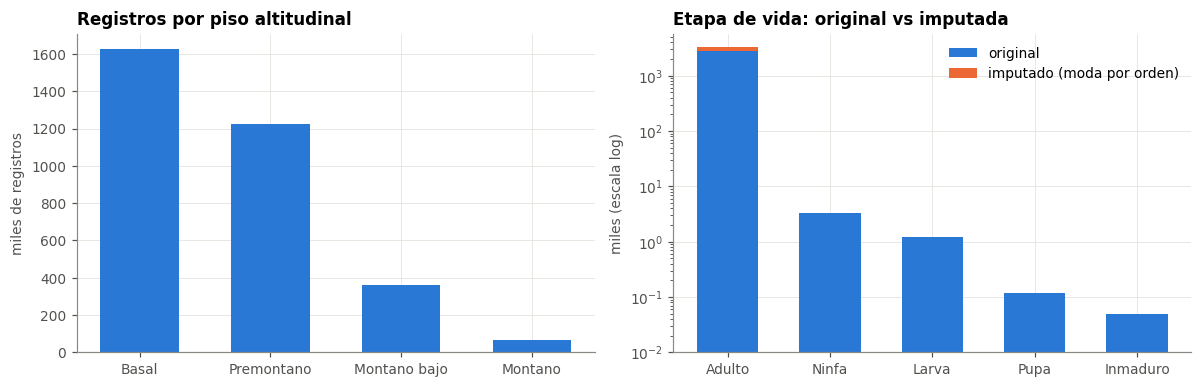

In [36]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
d = occ.groupBy("piso_altitudinal").count().toPandas().set_index("piso_altitudinal").reindex(
    ["Basal", "Premontano", "Montano bajo", "Montano"])
a1.bar(d.index, d["count"] / 1e3, color=AZUL, width=0.6)
a1.set_title("Registros por piso altitudinal"); a1.set_ylabel("miles de registros")
d = occ.groupBy("etapa_vida", "etapa_vida_imputada").count().toPandas().pivot(
    index="etapa_vida", columns="etapa_vida_imputada", values="count").fillna(0).sort_values(False, ascending=False)
a2.bar(d.index, d[False] / 1e3, color=AZUL, width=0.6, label="original")
a2.bar(d.index, d[True] / 1e3, bottom=d[False] / 1e3, color=NARANJA, width=0.6, label="imputado (moda por orden)")
a2.set_title("Etapa de vida: original vs imputada"); a2.set_yscale("log"); a2.set_ylim(0.01, None)
a2.set_ylabel("miles (escala log)")
a2.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpretación.** La mitad de los registros es del piso **Basal** (< 500 m: 1 626 505) y otro 37 % del
**Premontano** (1 222 925); el Montano bajo suma 362 972 y el **Montano** (≥ 2 500 m) solo 63 923 (2 %). El esfuerzo
de recolecta disminuye con la altitud, por la menor superficie y el difícil acceso de la alta montaña. En la etapa
de vida, «Adulto» domina con más del 98 % de los valores conocidos; la imputación por moda solo agrega registros
a esa barra (segmento naranja) y no altera la proporción de las etapas inmaduras, que siguen siendo marginales
(escala logarítmica).

## 5. Detección y análisis de anomalías

### 5.1 Selección de variables
Se usan cuatro variables numéricas continuas que describen **dónde y cuándo** se registró cada especímen:
`latitud`, `longitud`, `elevacion_m` y `anio`.
- La combinación **ubicación + elevación** permite detectar errores de georreferenciación: una elevación
  incoherente con el lugar (p. ej. 2 500 m en la costa) es una anomalía multivariada que ninguna variable revela
  por sí sola.
- `anio` detecta recolectas aisladas en el tiempo (inicio o final del programa de inventario).
- Se excluye `mes` (variable cíclica: diciembre y enero son vecinos) y las variables categóricas.
- Solo se analizan registros con **elevación original**: las elevaciones imputadas son medianas del vecindario y
  serían «normales» por construcción.

Las variables se estandarizan (media 0, desviación 1) para Isolation Forest y LOF, que son sensibles a la escala.

### 5.2 Algoritmos
| Algoritmo | Tipo | Idea | Implementación |
|---|---|---|---|
| **IQR (Tukey)** | Estadístico, univariado | Atípico si queda fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR] en alguna variable | 100 % Spark (`approxQuantile`) sobre todos los registros |
| **Isolation Forest** | Basado en árboles, multivariado | Los puntos anómalos se aíslan con pocas particiones aleatorias | scikit-learn: se entrena con una muestra de 200 000 registros y se **aplica a todos** en paralelo con `mapInPandas` de Spark |
| **LOF (Local Outlier Factor)** | Basado en densidad, multivariado | Anómalo si su densidad local es mucho menor que la de sus k vecinos | scikit-learn sobre una muestra estratificada de ≈50 000 registros (LOF requiere comparar cada punto con sus vecinos: O(n²) en el peor caso, inviable para 3 M en una sola máquina) |

MLlib no incluye Isolation Forest ni LOF; por eso se combinan con Spark de la forma más distribuida posible.

In [37]:
VARS = ["latitud", "longitud", "elevacion_m", "anio"]
base = (occ.where((F.col("fuente_elevacion") == "original") & F.col("anio").isNotNull())
           .select("id", *VARS, "orden", "piso_altitudinal", "provincia", "localidad"))
base.write.mode("overwrite").parquet(f"{TRABAJO}/anomalias_base.parquet")
base = spark.read.parquet(f"{TRABAJO}/anomalias_base.parquet")
N_BASE = base.count()
print(f"Registros para detección de anomalías: {miles(N_BASE)}")
base.select(VARS).summary("mean", "stddev", "min", "25%", "50%", "75%", "max").toPandas()

Registros para detección de anomalías: 3 267 433


,summary,latitud,longitud,elevacion_m,anio
0,mean,10.067270364525449,-84.35584782439089,660.3348992925027,1995.0238040076108
1,stddev,0.8171470785288683,0.9277001330717973,638.0296645283299,6.693959583192804
2,min,5.518489,-87.079722,0.0,1941
3,25%,9.632582,-85.373656,100.0,1991
4,50%,10.276723,-84.132806,500.0,1993
5,75%,10.776784,-83.591289,1100.0,1999
6,max,11.156395,-82.599032,3820.0,2015


### 5.3 Algoritmo 1 — Rango intercuartílico (IQR)

In [38]:
q = base.approxQuantile(VARS, [0.25, 0.75], 0.0005)
limites = {}
for v, (q1, q3) in zip(VARS, q):
    iqr = q3 - q1
    limites[v] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
display(pd.DataFrame(limites, index=["límite inferior", "límite superior"]).T.round(3))

for v, (lo, hi) in limites.items():
    base = base.withColumn(f"iqr_{v}", (F.col(v) < lo) | (F.col(v) > hi))
base = base.withColumn("anom_iqr", reduce(lambda a, b: a | b, [F.col(f"iqr_{v}") for v in VARS]))
res_iqr = base.agg(*[F.sum(F.col(f"iqr_{v}").cast("int")).alias(v) for v in VARS],
                   F.sum(F.col("anom_iqr").cast("int")).alias("total (alguna variable)")).toPandas().T
res_iqr.columns = ["anómalos"]; res_iqr["%"] = (100 * res_iqr["anómalos"] / N_BASE).round(2)
res_iqr

,límite inferior,límite superior
latitud,7.916,12.493
longitud,-88.047,-80.918
elevacion_m,-1400.000,2600.000
anio,1979.000,2011.000


,anómalos,%
latitud,7925,0.24
longitud,0,0.00
elevacion_m,36494,1.12
anio,117870,3.61
total (alguna variable),161314,4.94


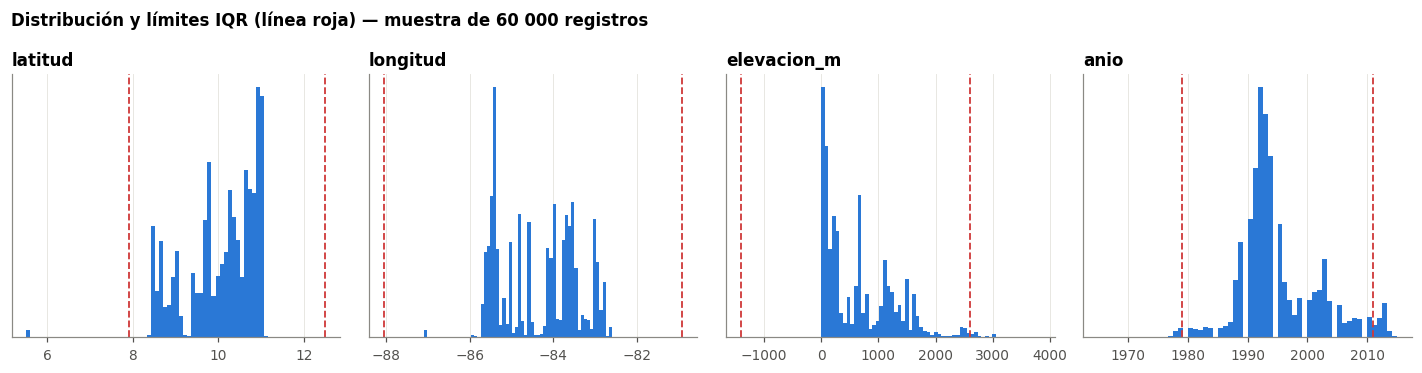

In [39]:
muestra_graf = base.sample(fraction=min(1.0, 60000 / N_BASE), seed=SEMILLA).toPandas()
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, v in zip(axs, VARS):
    ax.hist(muestra_graf[v], bins=60, color=AZUL)
    for lim in limites[v]:
        ax.axvline(lim, color=ROJO, lw=1.2, ls="--")
    ax.set_title(v); ax.set_yticks([])
fig.suptitle("Distribución y límites IQR (línea roja) — muestra de 60 000 registros", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación.** IQR marca 161 314 registros (4,9 %). La mayoría por **año** (3,6 %): el 50 % central de las
recolectas está entre 1991 y 1999, así que todo lo anterior a 1979 o posterior a 2011 queda fuera. Le sigue la
**elevación** (1,1 %): la distribución tiene una cola larga hacia la montaña y todo lo que supera 2 600 m sale como
«atípico», aunque sea perfectamente real (la Cordillera de Talamanca existe). En latitud solo marca la Isla del Coco
(0,2 %) y en longitud nada. Es una regla simple y transparente, pero **univariada** y dependiente de la forma de la
distribución.

### 5.4 Algoritmo 2 — Isolation Forest
Parámetros: 200 árboles, 256 muestras por árbol (valor de referencia del artículo original). Se calcula primero la
bandera con el umbral teórico del artículo (`contamination="auto"`, puntuación > 0,5) y, como se verá, marca una
fracción poco creíble del conjunto; la bandera final usa el **percentil 95** de la puntuación (contaminación
esperada del 5 %, del mismo orden que IQR). El escalador y el modelo se ajustan con una muestra aleatoria de
200 000 registros, se distribuyen a los ejecutores con un *broadcast* y Spark puntúa **todos** los registros.

In [40]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

muestra_if = base.select(VARS).sample(fraction=min(1.0, 200_000 / N_BASE), seed=SEMILLA).toPandas()
escalador = StandardScaler().fit(muestra_if[VARS])
iforest = IsolationForest(n_estimators=200, max_samples=256, contamination="auto",
                          random_state=SEMILLA, n_jobs=-1).fit(escalador.transform(muestra_if[VARS]))
modelo_b = spark.sparkContext.broadcast((escalador, iforest))

def puntuar_if(lotes):
    esc, modelo = modelo_b.value
    for pdf in lotes:
        X = esc.transform(pdf[VARS])
        yield pd.DataFrame({"id": pdf["id"], "score_if": -modelo.score_samples(X)})   # mayor = más anómalo

scores_if = base.select("id", *VARS).mapInPandas(puntuar_if, "id string, score_if double")
anom = base.join(scores_if, "id")
anom.write.mode("overwrite").parquet(f"{TRABAJO}/anomalias.parquet")
anom = spark.read.parquet(f"{TRABAJO}/anomalias.parquet")
UMBRAL_IF = anom.approxQuantile("score_if", [0.95], 0.0005)[0]
anom = (anom.withColumn("anom_if_auto", F.col("score_if") > 0.5)
            .withColumn("anom_if", F.col("score_if") > UMBRAL_IF))
anom.write.mode("overwrite").parquet(f"{TRABAJO}/anomalias_if.parquet")
anom = spark.read.parquet(f"{TRABAJO}/anomalias_if.parquet")
n_auto = anom.where("anom_if_auto").count()
n_if = anom.where("anom_if").count()
print(f"Umbral teórico (0,5):    {miles(n_auto)} anómalos ({100 * n_auto / N_BASE:.2f} %)")
print(f"Umbral percentil 95 ({UMBRAL_IF:.3f}): {miles(n_if)} anómalos ({100 * n_if / N_BASE:.2f} %)  ← bandera usada")

Umbral teórico (0,5):    844 028 anómalos (25.83 %)
Umbral percentil 95 (0.565): 164 120 anómalos (5.02 %)  ← bandera usada


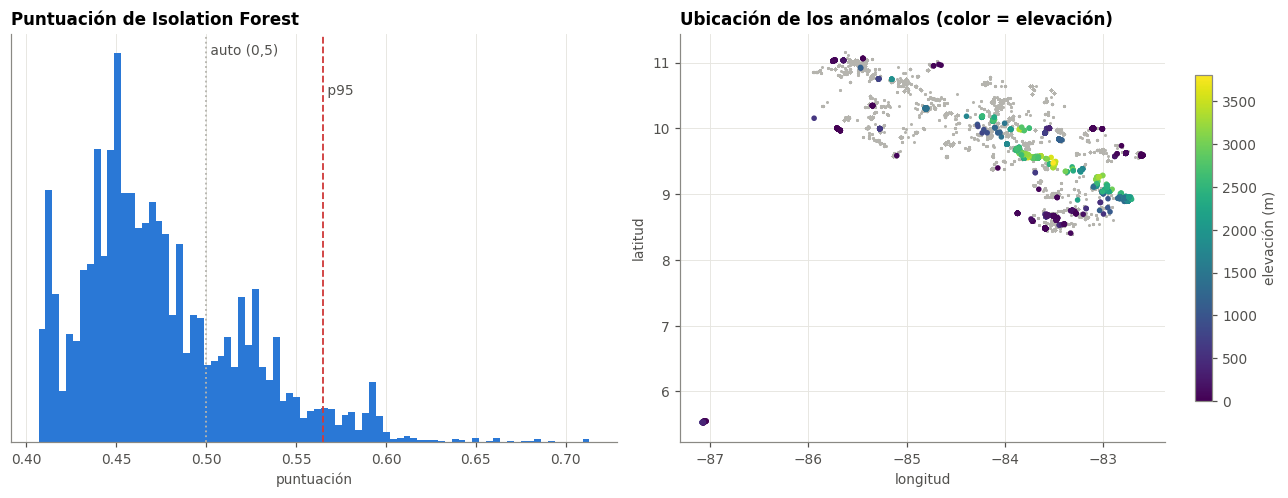

In [41]:
mg = anom.sample(fraction=min(1.0, 60000 / N_BASE), seed=SEMILLA).toPandas()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
a1.hist(mg["score_if"], bins=80, color=AZUL)
a1.axvline(0.5, color=GRIS, ls=":", lw=1.2); a1.text(0.5, a1.get_ylim()[1] * 0.95, " auto (0,5)", color=TINTA)
a1.axvline(UMBRAL_IF, color=ROJO, ls="--", lw=1.2); a1.text(UMBRAL_IF, a1.get_ylim()[1] * 0.85, " p95", color=TINTA)
a1.set_title("Puntuación de Isolation Forest"); a1.set_xlabel("puntuación"); a1.set_yticks([])
n_ = mg[~mg.anom_if]; a_ = mg[mg.anom_if]
a2.scatter(n_.longitud, n_.latitud, s=1, c=GRIS, label="normal", rasterized=True)
sc = a2.scatter(a_.longitud, a_.latitud, s=7, c=a_.elevacion_m, cmap="viridis", label="anómalo")
a2.set_title("Ubicación de los anómalos (color = elevación)"); a2.set_xlabel("longitud"); a2.set_ylabel("latitud")
plt.colorbar(sc, ax=a2, label="elevación (m)", shrink=0.8)
plt.tight_layout(); plt.show()

**Interpretación.** Con el umbral teórico (0,5) Isolation Forest marcaría el **25,8 %** del conjunto: los datos
tienen muchos puntos idénticos y grandes zonas poco muestreadas, por lo que la puntuación «normal» del artículo no
está calibrada para ellos. Con el percentil 95 se marcan 164 120 registros (5,0 %). Los más anómalos son los de la
**Isla del Coco** (lejos de todo en latitud/longitud y recolectados en 2013) y los de **alta montaña** de Talamanca:
regiones extremas en varias variables a la vez.

### 5.5 Algoritmo 3 — Local Outlier Factor (LOF)
Parámetros: `n_neighbors=20` (valor recomendado por los autores), `contamination="auto"` (anómalo si LOF > 1,5).
**Muestra estratificada** por piso altitudinal (`sampleBy` de Spark, misma fracción en cada estrato) de ≈50 000
registros, para que todas las zonas de vida estén representadas en la proporción original.

**Detalle técnico:** muchos especímenes comparten exactamente la misma ubicación, elevación y año (salieron de la
misma trampa). Con puntos repetidos la distancia a los vecinos es 0 y la densidad local se vuelve infinita, lo que
distorsiona LOF. Por eso LOF se ajusta sobre los **vectores únicos** de la muestra y la puntuación se asigna a
todos los registros que comparten ese vector.

In [42]:
from sklearn.neighbors import LocalOutlierFactor

frac = min(1.0, 50_000 / N_BASE)
estratos = [r[0] for r in anom.select("piso_altitudinal").distinct().collect()]
muestra_lof = anom.sampleBy("piso_altitudinal", fractions={p: frac for p in estratos}, seed=SEMILLA).toPandas()
X = escalador.transform(muestra_lof[VARS])
unicos, inverso = np.unique(X, axis=0, return_inverse=True)
lof = LocalOutlierFactor(n_neighbors=20, contamination="auto")
pred = lof.fit_predict(unicos)
muestra_lof["score_lof"] = -lof.negative_outlier_factor_[inverso.ravel()]
muestra_lof["anom_lof"] = pred[inverso.ravel()] == -1
N_LOF = len(muestra_lof)
print(f"Muestra LOF: {miles(N_LOF)} registros, {miles(len(unicos))} vectores únicos")
print(f"LOF: {miles(muestra_lof.anom_lof.sum())} anómalos ({100 * muestra_lof.anom_lof.mean():.2f} %)")
print(muestra_lof.groupby("piso_altitudinal").size().rename("registros en la muestra"))

Muestra LOF: 50 197 registros, 3 787 vectores únicos
LOF: 1 568 anómalos (3.12 %)
piso_altitudinal
Basal           25113
Montano           994
Montano bajo     5428
Premontano      18662
Name: registros en la muestra, dtype: int64


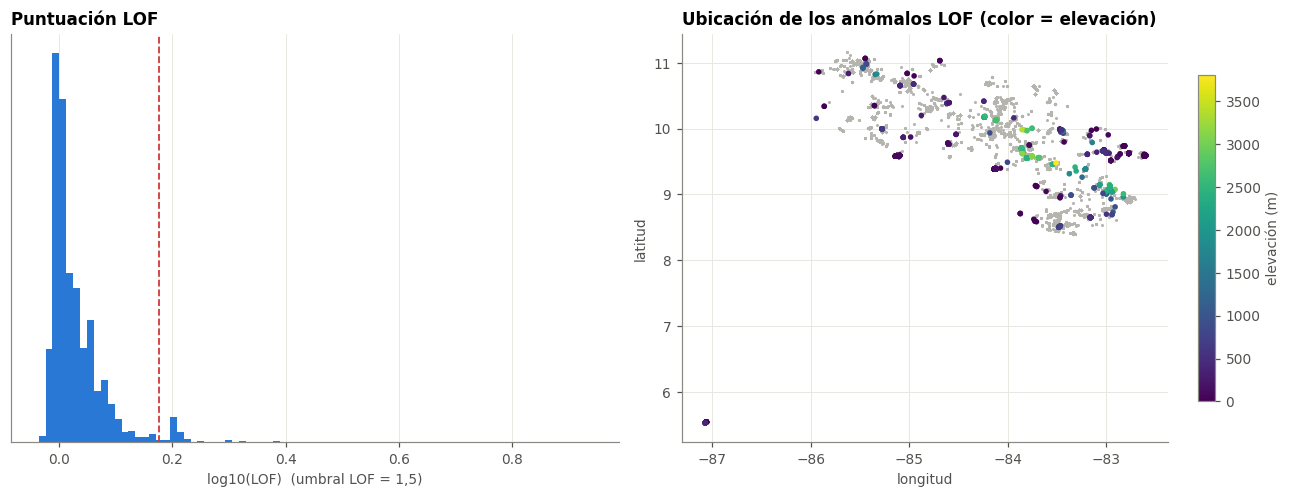

In [43]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
a1.hist(np.log10(muestra_lof["score_lof"]), bins=80, color=AZUL); a1.axvline(np.log10(1.5), color=ROJO, ls="--", lw=1.2)
a1.set_title("Puntuación LOF"); a1.set_xlabel("log10(LOF)  (umbral LOF = 1,5)"); a1.set_yticks([])
n_ = muestra_lof[~muestra_lof.anom_lof]; a_ = muestra_lof[muestra_lof.anom_lof]
a2.scatter(n_.longitud, n_.latitud, s=1, c=GRIS, rasterized=True)
sc = a2.scatter(a_.longitud, a_.latitud, s=7, c=a_.elevacion_m, cmap="viridis")
a2.set_title("Ubicación de los anómalos LOF (color = elevación)"); a2.set_xlabel("longitud"); a2.set_ylabel("latitud")
plt.colorbar(sc, ax=a2, label="elevación (m)", shrink=0.8)
plt.tight_layout(); plt.show()

**Interpretación.** La gran mayoría de los registros tiene un LOF cercano a 1 (log10 ≈ 0): su densidad local es
igual a la de sus vecinos. La cola derecha, por encima del umbral de 1,5, son los anómalos (≈3 %). En el mapa se ve
que **no se concentran en una región**: aparecen dispersos junto a zonas densamente muestreadas de tierras bajas,
donde un punto con una elevación o un año distintos a los de sus vecinos inmediatos destaca, y en sitios de páramo
de Talamanca con muy pocos registros cerca.

### 5.6 Comparación de los tres algoritmos
Para comparar en igualdad de condiciones se usan los registros de la muestra de LOF, donde los tres algoritmos
tienen resultado (IQR e Isolation Forest se calcularon para todo el conjunto). Las puntuaciones de LOF, calculadas
con scikit-learn, se devuelven a Spark y **toda la comparación se hace con agregaciones de Spark**: una sola pasada
calcula los conteos, las intersecciones y las uniones para el índice de Jaccard.

In [44]:
# Resultados de LOF -> Spark; se unen con las banderas de IQR e Isolation Forest de la misma muestra.
lof_sdf = spark.createDataFrame(muestra_lof[["id", "score_lof", "anom_lof"]])
comp = anom.join(lof_sdf, "id").cache()
N_COMP = comp.count()
FLAGS = {"IQR": "anom_iqr", "IF": "anom_if", "LOF": "anom_lof"}

total = anom.agg(*[F.sum(F.col(c).cast("int")).alias(k) for k, c in list(FLAGS.items())[:2]]).first()
en_muestra = comp.agg(*[F.sum(F.col(c).cast("int")).alias(k) for k, c in FLAGS.items()]).first()
resumen = pd.DataFrame({
    "anómalos (conjunto completo)": [total["IQR"], total["IF"], None],
    "% (conjunto completo)": [round(100 * total["IQR"] / N_BASE, 2), round(100 * total["IF"] / N_BASE, 2), None],
    "anómalos (muestra LOF)": [en_muestra[k] for k in FLAGS],
    "% (muestra LOF)": [round(100 * en_muestra[k] / N_COMP, 2) for k in FLAGS],
}, index=["IQR", "Isolation Forest", "LOF"])
display(resumen)

# Intersección y unión de cada par en una sola agregación -> índice de Jaccard
pares = comp.agg(
    *[F.sum((F.col(a) & F.col(b)).cast("int")).alias(f"y_{x}_{y}") for x, a in FLAGS.items() for y, b in FLAGS.items()],
    *[F.sum((F.col(a) | F.col(b)).cast("int")).alias(f"o_{x}_{y}") for x, a in FLAGS.items() for y, b in FLAGS.items()]).first()
coinc = pd.DataFrame([[f"{pares[f'y_{x}_{y}'] / max(pares[f'o_{x}_{y}'], 1):.2f}  ({pares[f'y_{x}_{y}']})" for y in FLAGS]
                      for x in FLAGS], index=list(FLAGS), columns=list(FLAGS))
print(f"Registros comparados: {miles(N_COMP)}")
print("Coincidencia: índice de Jaccard (y cantidad de registros marcados por ambos)")
display(coinc)

# Combinaciones: qué algoritmos marcaron cada registro
etiqueta = F.concat_ws(" + ", *[F.when(F.col(c), F.lit(k)) for k, c in FLAGS.items()])
combo = (comp.withColumn("algoritmos", F.when(etiqueta == "", "ninguno").otherwise(etiqueta))
             .groupBy("algoritmos").count().orderBy(F.desc("count"))
             .toPandas().set_index("algoritmos").rename(columns={"count": "registros"}))
combo

,anómalos (conjunto completo),% (conjunto completo),anómalos (muestra LOF),% (muestra LOF)
IQR,161314.0,4.94,2497,4.97
Isolation Forest,164120.0,5.02,2475,4.93
LOF,NaN,NaN,1568,3.12


Registros comparados: 50 197
Coincidencia: índice de Jaccard (y cantidad de registros marcados por ambos)


,IQR,IF,LOF
IQR,1.00 (2497),0.24 (966),0.02 (91)
IF,0.24 (966),1.00 (2475),0.09 (327)
LOF,0.02 (91),0.09 (327),1.00 (1568)


,registros
algoritmos,
ninguno,44951
IQR,1530
IF,1272
LOF,1240
IQR + IF,876
IF + LOF,237
IQR + IF + LOF,90
IQR + LOF,1


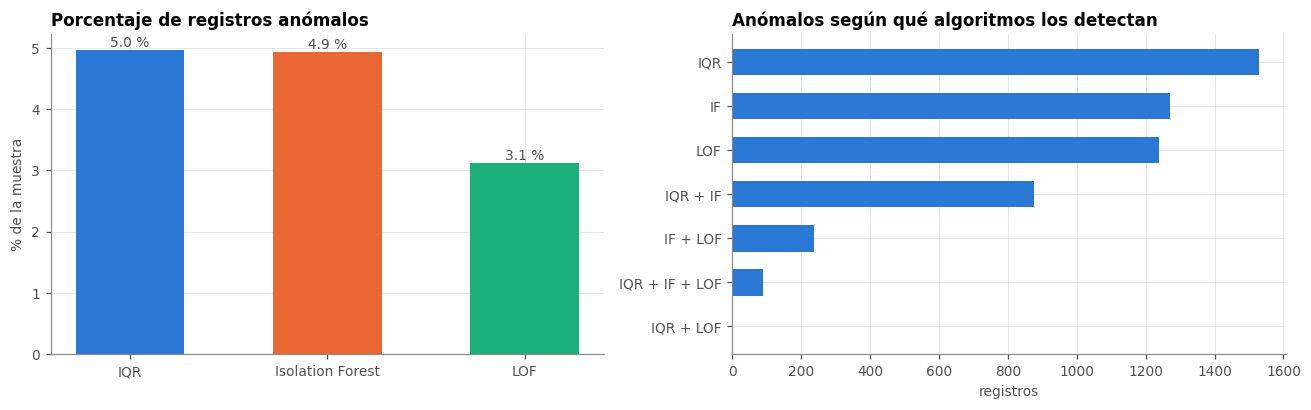

In [45]:
c = combo.drop("ninguno", errors="ignore")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.bar(resumen.index, resumen["% (muestra LOF)"], color=[AZUL, NARANJA, AQUA], width=0.55)
for i, v in enumerate(resumen["% (muestra LOF)"]):
    a1.text(i, v, f"{v:.1f} %", ha="center", va="bottom", color=TINTA)
a1.set_title("Porcentaje de registros anómalos"); a1.set_ylabel("% de la muestra")
a2.barh(c.index, c["registros"], color=AZUL, height=0.6); a2.invert_yaxis()
a2.set_title("Anómalos según qué algoritmos los detectan"); a2.set_xlabel("registros")
plt.tight_layout(); plt.show()

**Interpretación.** Con umbrales comparables, IQR e Isolation Forest marcan cerca del 5 % de la muestra y LOF
alrededor del 3 %. El gráfico de combinaciones muestra que **la mayoría de los registros anómalos los detecta un
solo algoritmo**: cada método tiene su propia noción de «anómalo». La intersección más grande es IQR + Isolation
Forest (ambos reaccionan a valores globalmente extremos), mientras que LOF casi no coincide con IQR. El grupo
marcado por los tres es muy pequeño.

**Características de los registros anómalos** (medianas de las variables y orden más frecuente, por algoritmo):

,registros,mediana latitud,mediana longitud,mediana elevacion_m,mediana anio,orden más frecuente,piso más frecuente
grupo,,,,,,,
normal (ninguno),44951,10.34,-84.55,375.0,1993,Coleoptera,Basal
IQR,2497,10.05,-84.02,1600.0,2012,Diptera,Montano bajo
Isolation Forest,2475,9.56,-83.67,2450.0,1997,Diptera,Montano
LOF,1568,9.39,-84.13,80.0,1992,Lepidoptera,Basal
los tres,90,9.40,-84.07,1150.0,2006,Coleoptera,Montano


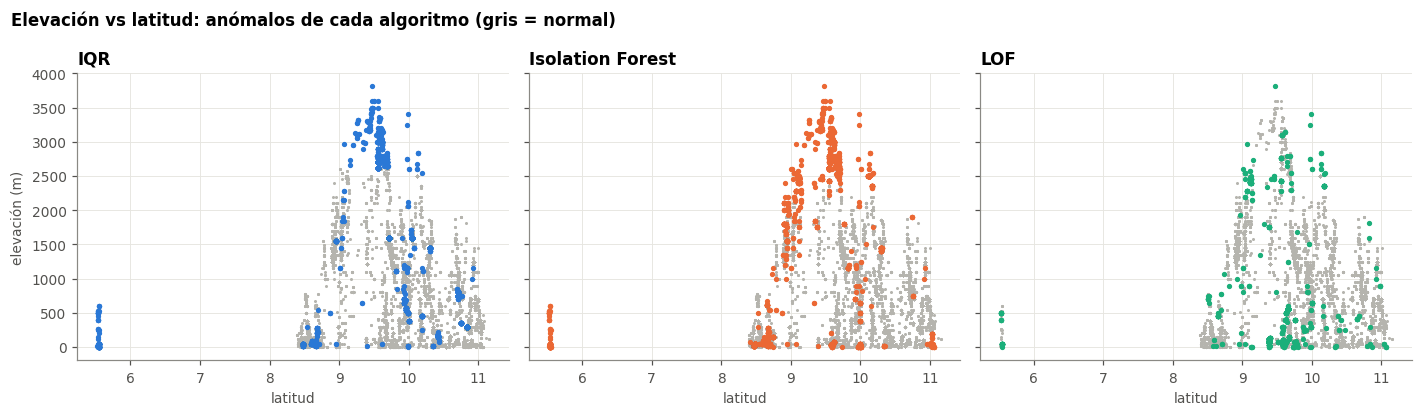

Registros más anómalos según cada algoritmo:


,id,latitud,longitud,elevacion_m,anio,orden,localidad,score_if
0,urn:catalog:INB:Atta:4350967,5.544444,-87.056131,50.0,2013,Lepidoptera,P. N. Isla del Coco. Orilla del Río Genio,0.713150
1,urn:catalog:INB:Atta:4351155,5.544444,-87.054722,50.0,2013,No determinado,"Isla del Coco, Bahía Wafer, Estación Las Villas.",0.713150
2,urn:catalog:INB:Atta:4350993,5.544444,-87.054722,50.0,2013,No determinado,"Isla del Coco, Bahía Wafer, Estación Las Villas.",0.713150
3,urn:catalog:INB:Atta:4350971,5.544444,-87.056131,50.0,2013,Lepidoptera,P. N. Isla del Coco. Orilla del Río Genio,0.713150
4,urn:catalog:INB:Atta:4351029,5.544444,-87.054722,50.0,2013,Hymenoptera,"Isla del Coco, Bahía Wafer, Estación Las Villas.",0.713150
5,urn:catalog:INB:Atta:4351514,5.530397,-87.066311,500.0,2013,No determinado,"P. N. Isla del Coco, bosque nuboso sobre el sendero a Cerro Yglesias.",0.710789


,id,latitud,longitud,elevacion_m,anio,orden,localidad,score_lof
0,urn:catalog:INB:Atta:3753032,9.415485,-83.318207,2450.0,2003,Diptera,"Talamanca, Sabanas Dúrika.",8.720624
1,urn:catalog:INB:Atta:3724255,9.149555,-82.968825,2730.0,2003,Diptera,Cerros Tararia,7.611028
2,urn:catalog:INB:Atta:3950305,9.075324,-82.911898,2966.0,2005,Coleoptera,"Coto Brus, Sector Pittier, Las Huacas, Send. a Fábrega.",7.495604
3,urn:catalog:INB:Atta:3752969,9.355299,-83.307076,2340.0,2003,No determinado,"Buenos Aires, Los Cipresés.",7.254954
4,urn:catalog:INB:Atta:4134793,9.147016,-83.067086,2250.0,2008,Coleoptera,Tres Colinas,6.308890
5,urn:catalog:INB:Atta:4134783,9.143854,-83.068456,2250.0,2008,No determinado,Tres Colinas,6.308794


In [46]:
def moda(df, c):
    r = df.groupBy(c).count().orderBy(F.desc("count"), c).first()
    return r[0] if r else None

todos = F.col("anom_iqr") & F.col("anom_if") & F.col("anom_lof")
ninguno = ~(F.col("anom_iqr") | F.col("anom_if") | F.col("anom_lof"))
filas = []
for nombre, cond in [("normal (ninguno)", ninguno), ("IQR", F.col("anom_iqr")), ("Isolation Forest", F.col("anom_if")),
                     ("LOF", F.col("anom_lof")), ("los tres", todos)]:
    s = comp.where(cond)
    est = s.agg(F.count("*").alias("registros"),
                *[F.round(F.percentile_approx(v, 0.5), 2).alias(f"mediana {v}") for v in VARS]).first().asDict()
    filas.append({"grupo": nombre, **est, "orden más frecuente": moda(s, "orden"),
                  "piso más frecuente": moda(s, "piso_altitudinal")})
display(pd.DataFrame(filas).set_index("grupo"))

# Gráfico: se traen a pandas solo las columnas necesarias para dibujar
m = comp.select("latitud", "elevacion_m", *FLAGS.values()).toPandas()
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (nombre, col, color) in zip(axs, [("IQR", "anom_iqr", AZUL), ("Isolation Forest", "anom_if", NARANJA), ("LOF", "anom_lof", AQUA)]):
    ax.scatter(m.latitud[~m[col]], m.elevacion_m[~m[col]], s=1, c=GRIS, rasterized=True)
    ax.scatter(m.latitud[m[col]], m.elevacion_m[m[col]], s=6, c=color)
    ax.set_title(nombre); ax.set_xlabel("latitud")
axs[0].set_ylabel("elevación (m)")
fig.suptitle("Elevación vs latitud: anómalos de cada algoritmo (gris = normal)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
print("Registros más anómalos según cada algoritmo:")
for col in ["score_if", "score_lof"]:
    display(comp.orderBy(F.desc(col)).select("id", *VARS, "orden", "localidad", col).limit(6).toPandas())

### 5.7 Conclusiones de la detección de anomalías
- **Cantidad.** En la muestra común de ≈50 000 registros, IQR marca 5,0 %, Isolation Forest 4,9 % (umbral p95)
  y LOF 3,1 %. La cantidad de IQR y LOF sale de la regla de cada método; la de Isolation Forest depende del umbral:
  con el teórico habría marcado una cuarta parte del conjunto, lo que muestra lo sensible que es a ese parámetro.
- **Coincidencia.** Es baja: Jaccard IQR–IF = 0,24, IF–LOF = 0,09 e IQR–LOF = 0,02. Solo 90 registros (0,2 %) son
  marcados por los tres. Los algoritmos miden cosas distintas:
  - **IQR** marca sobre todo **años recientes** (mediana 2012) y elevaciones altas: extremos de una sola variable.
  - **Isolation Forest** marca combinaciones globalmente raras: **alta montaña** (mediana 2 450 m, piso Montano) e
    Isla del Coco. Coincide más con IQR porque ambos reaccionan a valores globalmente extremos.
  - **LOF** marca **anomalías locales en tierras bajas** (mediana 80 m): puntos cuya combinación ubicación–elevación–año
    no se parece a la de sus vecinos inmediatos, aunque cada valor por separado sea común. Sus casos más altos son
    sitios de páramo de Talamanca con muy pocos registros vecinos (Sabanas Dúrika, Cerros Tararia).
  - Los 90 registros marcados por los tres son sitios de montaña con pocas recolectas, los más dignos de revisión.
- **Ventajas y limitaciones.** IQR es simple, explicable y 100 % distribuible en Spark, pero univariado y
  confunde «raro» con «erróneo» en distribuciones asimétricas. Isolation Forest es multivariado, escala a todo
  el dataset y no supone distribución alguna, pero su umbral es arbitrario y favorece los extremos globales.
  LOF es el único que capta incoherencias locales (el tipo de error de georreferenciación que más interesa), pero
  es costoso, sensible a duplicados exactos y a `k`, y aquí solo se pudo aplicar a una muestra.
- **Más apropiado para estos datos.** Para validar la coherencia ubicación–elevación, **LOF** es el más
  adecuado conceptualmente e **Isolation Forest** el más práctico para todo el conjunto. IQR sirve como
  filtro de valores fuera de rango, no como detector de errores en datos con gradientes naturales tan
  fuertes.
- **Decisión.** Los registros anómalos **no se eliminan**: la mayoría corresponde a hábitats reales y poco
  muestreados (alta montaña, islas, años iniciales), que son justamente de interés para el estudio. Los valores
  imposibles ya se trataron con reglas de dominio en §3.6.

## 6. Integración de los conjuntos de datos (join espacial con Apache Sedona)

### 6.1 Preparación de las áreas protegidas
- **Proyección:** la capa está en CRTM05 (EPSG:5367, metros). Se transforma a WGS84 (EPSG:4326, grados) con
  `ST_Transform` para compararla con las coordenadas de GBIF. Se conserva también la geometría en CRTM05 para
  medir distancias en metros.
- **Validez:** se aplica `ST_MakeValid` a cualquier polígono inválido, también **después** de reproyectar
  (la reproyección puede generar auto-intersecciones mínimas en vértices muy cercanos).
- **Identificador:** como `codigo` no es único (§2.7), cada polígono recibe un `id_poligono` determinístico
  (orden por código, tipo y área). Todos los joins usan este identificador; si se usara `codigo`, cada ocurrencia
  se multiplicaría por la cantidad de polígonos con ese código.
- **Área:** `area_poligono_km2` es el área de cada parte (se usa para resolver solapes) y `area_protegida_km2` el
  área total del ASP (suma de sus partes con el mismo código y nombre), que es el valor que se exporta a Solr.
- **Textos:** la capa no tiene tildes («Cano Negro», «Reserva Biologica») y tiene mayúsculas inconsistentes
  («Isla San lucas»). Se restauran las tildes con un diccionario de palabras y se capitaliza cada palabra de 4 o
  más letras (los conectores «de», «del», «la», «y» quedan en minúscula). Así los valores coinciden con los de
  la aplicación (p. ej. «Reserva Biológica»).

In [47]:
TILDES = {"Area": "Área", "Areas": "Áreas", "Biologica": "Biológica", "Conservacion": "Conservación",
          "Administracion": "Administración", "Acuiferos": "Acuíferos", "Guacimo": "Guácimo", "Pococi": "Pococí",
          "Bahia": "Bahía", "Cano": "Caño", "Canas": "Cañas", "Chirripo": "Chirripó", "Escazu": "Escazú",
          "Curu": "Curú", "Diria": "Diriá", "Baru": "Barú", "Pacifico": "Pacífico", "Rio": "Río", "Volcan": "Volcán",
          "Volcanica": "Volcánica", "Irazu": "Irazú", "Poas": "Poás", "Montana": "Montaña", "Nicolas": "Nicolás",
          "Pajaros": "Pájaros", "Peninsula": "Península", "Portalon": "Portalón", "Rincon": "Rincón",
          "Tapanti": "Tapantí", "Terraba": "Térraba", "Tiribi": "Tiribí", "Zapandi": "Zapandí", "Cipanci": "Cipancí"}

def estandarizar_texto(df, c):
    df = df.withColumn("__tmp__", F.regexp_replace(F.trim(F.col(c)), r"\s+", " "))
    df = df.withColumn("__tmp__", F.array_join(F.expr(
        "transform(split(__tmp__, ' '), w -> CASE WHEN length(w) >= 4 THEN concat(upper(substr(w, 1, 1)), substr(w, 2)) ELSE w END)"), " "))
    for sin, con in TILDES.items():
        df = df.withColumn("__tmp__", F.regexp_replace("__tmp__", rf"\b{sin}\b", con))
    return df.withColumn(c, F.col("__tmp__")).drop("__tmp__")

asp = asp_crudo
for c in ["nombre_asp", "cat_manejo", "nombre_ac", "descripcio"]:
    asp = estandarizar_texto(asp, c)
w_id = Window.orderBy("codigo", "descripcio", F.col("area_km2").cast("double"))
w_asp = Window.partitionBy("codigo", "nombre_asp")
asp = (asp.withColumn("id_poligono", F.row_number().over(w_id))
          .withColumn("area_poligono_km2", F.col("area_km2").cast("double"))
          .withColumn("area_total_km2", F.sum(F.col("area_km2").cast("double")).over(w_asp))
          .withColumn("geom_crtm", F.expr("CASE WHEN ST_IsValid(geometry) THEN geometry ELSE ST_MakeValid(geometry) END"))
          .withColumn("geom", F.expr("ST_MakeValid(ST_Transform(geom_crtm, 'EPSG:5367', 'EPSG:4326'))"))
          .select("id_poligono", "codigo", F.col("nombre_asp").alias("area_protegida"), F.col("cat_manejo").alias("categoria_manejo"),
                  F.col("siglas_ac").alias("area_conservacion"), F.col("nombre_ac").alias("nombre_area_conservacion"),
                  F.col("descripcio").alias("tipo_asp"), "area_poligono_km2", F.col("area_total_km2").alias("area_protegida_km2"),
                  "geom", "geom_crtm"))
asp.cache()
print("Polígonos:", asp.count(), "| inválidos en WGS84:", asp.where(F.expr("NOT ST_IsValid(geom)")).count(),
      "| inválidos en CRTM05:", asp.where(F.expr("NOT ST_IsValid(geom_crtm)")).count())
print("id_poligono únicos:", asp.select("id_poligono").distinct().count())
ver(asp.select("id_poligono", "codigo", "area_protegida", "categoria_manejo", "area_conservacion", "tipo_asp", "area_poligono_km2", "area_protegida_km2",
               F.expr("ST_AsText(ST_Centroid(geom))").alias("centroide_wgs84")), 12)

Polígonos: 173 | inválidos en WGS84: 0 | inválidos en CRTM05: 0
id_poligono únicos: 173


,id_poligono,codigo,area_protegida,categoria_manejo,area_conservacion,tipo_asp,area_poligono_km2,area_protegida_km2,centroide_wgs84
0,1,A01,Montes Submarinos,Área Marina de Manejo,ACMC,Área Marina de Manejo,106331.964022,106331.964022,POINT (-87.54284650259147 4.125074589173045)
1,2,A02,Cabo Blanco,Área Marina de Manejo,ACT,Área Marina de Manejo,824.701229,824.701229,POINT (-85.11865300047927 9.558005454165107)
2,3,A03,Bahía Santa Elena,Área Marina de Manejo,ACG,Área Marina de Manejo,7.230415,7.230415,POINT (-85.80271370881545 10.9255475108395)
3,4,A04,Barra del Colorado,Área Marina de Manejo,ACTo,Área Marina de Manejo,651.661831,651.661831,POINT (-83.49415264126489 10.892867521394777)
4,5,B01,Alberto Manuel Brenes,Reserva Biológica,ACC,Área Terrestre Protegida,78.004032,78.004032,POINT (-84.63096981082958 10.24044186764793)
5,6,B02,Isla del Caño,Reserva Biológica,ACOSA,Isla,3.260103,55.285020,POINT (-83.87919287555118 8.706469173511454)
6,7,B02,Isla del Caño,Reserva Biológica,ACOSA,Área Marina Protegida,52.024916,55.285020,POINT (-83.8797601855806 8.706885543960885)
7,8,B03,Isla Guayabo,Reserva Biológica,ACT,Isla,0.062681,0.062681,POINT (-84.87880440136244 9.911545617837337)
8,9,B04,Isla Pájaros,Reserva Biológica,ACOPAC,Isla,0.032116,0.032116,POINT (-84.99653110161671 10.09386860309569)
9,10,B05,Islas Negritos,Reserva Biológica,ACT,Isla,1.212199,1.212199,POINT (-84.84834152856158 9.821672091008748)


In [48]:
print(asp.groupBy("categoria_manejo").count().orderBy(F.desc("count")).toPandas().to_string(index=False))
print("\nNombres que cambiaron:")
cambios = (asp.select("codigo", "area_protegida").distinct()
           .join(asp_crudo.select("codigo", F.col("nombre_asp").alias("original")).distinct(), "codigo")
           .where("area_protegida <> original AND lower(translate(area_protegida, 'áéíóúñÁ', 'aeiounA')) = lower(original)"))
print(cambios.count()); ver(cambios, 15)

                  categoria_manejo  count
Refugio Nacional de Vida Silvestre     55
                   Parque Nacional     43
                   Zona Protectora     33
                           Humedal     13
                 Reserva Biológica     10
                  Reserva Forestal     10
             Área Marina de Manejo      4
          Reserva Natural Absoluta      4
                Monumento Nacional      1

Nombres que cambiaron:


43


,codigo,area_protegida,original
0,A03,Bahía Santa Elena,Bahia Santa Elena
1,B02,Isla del Caño,Isla del Cano
2,B04,Isla Pájaros,Isla Pajaros
3,H09,Palustrino Corral de Piedra,Palustrino Corral de piedra
4,H11,Riberino Zapandí,Riberino Zapandi
5,H12,Térraba-Sierpe,Terraba-Sierpe
6,H13,Humedal Lacustrino Río Cañas,Humedal lacustrino Rio Canas
7,N02,Nicolás Wessberg,Nicolas Wessberg
8,P04,Volcán Turrialba,Volcan Turrialba
9,P05,Volcán Poás,Volcan Poas


### 6.2 Atributo de relación y tipo de join
- **Atributo:** la geometría. En GBIF se construye un punto `ST_Point(longitud, latitud)`; en SINAC, el polígono
  del ASP en WGS84.
- **Predicado:** `ST_Contains(polígono, punto)`; el resultado guarda el `id_poligono`.
- **Estrategia:** Sedona optimiza el join espacial *interno* con un índice espacial (R-tree) sobre el lado pequeño
  difundido a todos los ejecutores (*broadcast index join*: 173 polígonos frente a ≈3,3 M de puntos). El resultado
  se lleva luego al conjunto de ocurrencias con un **LEFT JOIN por `id`**.
- **¿Por qué LEFT JOIN?** El objetivo incluye comparar lo que ocurre **dentro y fuera** de las ASP; un INNER JOIN
  perdería todos los registros fuera de las áreas. Con LEFT JOIN cada ocurrencia se conserva exactamente una vez;
  las que no caen en ninguna ASP quedan con `dentro_asp = false`.

In [49]:
puntos = occ.withColumn("punto", F.expr("ST_Point(longitud, latitud)"))
N_ANTES = puntos.count()
puntos.createOrReplaceTempView("ocurrencias")
asp.createOrReplaceTempView("asp")
t0 = time.time()
coincidencias = sedona.sql('''
    SELECT /*+ BROADCAST(a) */ o.id, a.id_poligono, a.area_poligono_km2
    FROM ocurrencias o JOIN asp a ON ST_Contains(a.geom, o.punto)''')
coincidencias.write.mode("overwrite").parquet(f"{TRABAJO}/coincidencias.parquet")
coincidencias = spark.read.parquet(f"{TRABAJO}/coincidencias.parquet")
n_pares = coincidencias.count()
n_ids = coincidencias.select("id").distinct().count()
print(f"Join espacial: {time.time() - t0:.0f} s")
print(f"Ocurrencias antes del join:            {miles(N_ANTES)}")
print(f"Pares (ocurrencia, ASP) encontrados:   {miles(n_pares)}")
print(f"Ocurrencias distintas dentro de ASP:   {miles(n_ids)}")
print(f"Ocurrencias en más de un ASP (solape): {miles(n_pares - n_ids)} pares extra")

Join espacial: 8 s
Ocurrencias antes del join:            3 276 325
Pares (ocurrencia, ASP) encontrados:   2 065 966
Ocurrencias distintas dentro de ASP:   2 064 839
Ocurrencias en más de un ASP (solape): 1 127 pares extra


### 6.3 Solapes entre áreas protegidas
Algunas ASP se superponen (p. ej. un refugio de vida silvestre y un área marina de manejo con el mismo nombre, o
un humedal dentro de un parque nacional). Una ocurrencia en la zona de solape aparece en dos pares: si se uniera
sin más, el registro **se duplicaría**. Regla aplicada: se asigna el **polígono de menor área**, la unidad de manejo
más específica que contiene al punto (en empate, el menor `id_poligono` para que sea determinístico).

In [50]:
nombres = asp.select("id_poligono", "area_protegida", "categoria_manejo", "tipo_asp")
solapes = (coincidencias.groupBy("id").agg(F.sort_array(F.collect_list("id_poligono")).alias("poligonos")).where(F.size("poligonos") > 1)
           .groupBy("poligonos").count().orderBy(F.desc("count")))
sl = solapes.toPandas()
mapa_nombres = {r.id_poligono: f"{r.area_protegida} ({r.categoria_manejo}, {r.tipo_asp})" for r in nombres.collect()}
sl["áreas"] = sl.poligonos.apply(lambda cs: " ∩ ".join(mapa_nombres[c] for c in cs))
display(sl[["áreas", "count"]].rename(columns={"count": "ocurrencias"}))

w = Window.partitionBy("id").orderBy("area_poligono_km2", "id_poligono")
asignacion = coincidencias.withColumn("r", F.row_number().over(w)).where("r = 1").select("id", "id_poligono")
print("Asignaciones (una por ocurrencia):", miles(asignacion.count()))

,áreas,ocurrencias
0,"Isla San Lucas (Parque Nacional, Isla) ∩ Isla San Lucas (Parque Nacional, Ár...",1124
1,"Térraba-Sierpe (Humedal, Área Terrestre Protegida) ∩ Golfo Dulce (Reserva Fo...",3


Asignaciones (una por ocurrencia): 2 064 839


### 6.4 Integración, distancia al borde y verificación de conteos
`distancia_borde_m` (variable derivada) es la distancia en metros del punto al límite de su ASP, calculada en
CRTM05 (proyección métrica oficial de Costa Rica) para que la medida sea exacta.

In [51]:
atributos = asp.drop("geom", "geom_crtm")
integrado = (occ.join(asignacion, "id", "left")
                .join(F.broadcast(atributos), "id_poligono", "left")
                .withColumn("dentro_asp", F.col("id_poligono").isNotNull())
                .withColumn("area_protegida", F.coalesce("area_protegida", F.lit("Fuera de ASP")))
                .withColumn("categoria_manejo", F.coalesce("categoria_manejo", F.lit("Sin categoría")))
                .withColumn("area_conservacion", F.coalesce("area_conservacion", F.lit("Sin área de conservación"))))

integrado.withColumn("punto", F.expr("ST_Point(longitud, latitud)")).createOrReplaceTempView("integrado")
distancias = sedona.sql('''
    SELECT /*+ BROADCAST(a) */ i.id,
           ST_Distance(ST_Transform(i.punto, 'EPSG:4326', 'EPSG:5367'), ST_Boundary(a.geom_crtm)) AS distancia_borde_m
    FROM integrado i JOIN asp a ON i.id_poligono = a.id_poligono''')
integrado = integrado.join(distancias, "id", "left")
integrado.write.mode("overwrite").parquet(f"{TRABAJO}/integrado.parquet")
integrado = spark.read.parquet(f"{TRABAJO}/integrado.parquet")

N_DESPUES = integrado.count()
ids_unicos = integrado.select("id").distinct().count()
dentro = integrado.where("dentro_asp").count()
print(f"Antes del join: {miles(N_ANTES)} | después: {miles(N_DESPUES)} | ids únicos: {miles(ids_unicos)}")
print(f"Dentro de ASP: {miles(dentro)} ({100 * dentro / N_DESPUES:.1f} %) | fuera (sin correspondencia): "
      f"{miles(N_DESPUES - dentro)} ({100 * (N_DESPUES - dentro) / N_DESPUES:.1f} %)")
assert N_DESPUES == N_ANTES, "El join perdió o duplicó registros"
assert ids_unicos == N_DESPUES, "Hay ocurrencias duplicadas después del join"
assert integrado.where("latitud IS NULL OR longitud IS NULL").count() == 0
assert N_DESPUES >= 100_000, "Menos de 100 000 registros geográficos válidos"
registrar("5. Integrado con ASP (left join)", integrado)
integrado.where("dentro_asp").select("distancia_borde_m").summary("min", "25%", "50%", "75%", "max").toPandas()

Antes del join: 3 276 325 | después: 3 276 325 | ids únicos: 3 276 325
Dentro de ASP: 2 064 839 (63.0 %) | fuera (sin correspondencia): 1 211 486 (37.0 %)
5. Integrado con ASP (left join): 3 276 325


,summary,distancia_borde_m
0,min,0.5661265702370968
1,25%,291.0026251593254
2,50%,730.4887996302026
3,75%,2486.299083980603
4,max,8541.854742468962


### 6.5 Consistencia y significado de la integración
1. **Sin pérdidas ni duplicados:** verificado con las aserciones anteriores (mismo conteo, ids únicos).
2. **Coherencia con el texto de localidad:** si el join es correcto, buena parte de las ocurrencias asignadas a un
   ASP deberían mencionar ese nombre en su localidad (el INBio escribe p. ej. «P.N. Corcovado, Estación
   Sirena»). Se compara el nombre (sin tildes, en minúsculas) con la localidad.
3. **Coherencia provincia–área de conservación:** se revisa que cada área de conservación concentre sus
   registros en las provincias donde realmente está.

In [52]:
sin_tildes = lambda c: F.lower(F.translate(F.col(c), "áéíóúüñÁÉÍÓÚÜÑ", "aeiouunAEIOUUN"))
chk = (integrado.where("dentro_asp")
       .withColumn("menciona", F.coalesce(sin_tildes("localidad").contains(sin_tildes("area_protegida")), F.lit(False))))
tot = chk.count(); men = chk.where("menciona").count()
print(f"Ocurrencias dentro de ASP cuya localidad menciona el nombre del ASP asignado: {miles(men)} de {miles(tot)} ({100 * men / tot:.1f} %)")
display(chk.groupBy("area_protegida").agg(F.count("*").alias("ocurrencias"), F.round(100 * F.avg(F.col("menciona").cast("int")), 1).alias("% menciona"))
        .orderBy(F.desc("ocurrencias")).limit(12).toPandas())
display(integrado.where("dentro_asp").groupBy("area_conservacion").pivot("provincia").count().fillna(0).orderBy("area_conservacion").toPandas())

Ocurrencias dentro de ASP cuya localidad menciona el nombre del ASP asignado: 814 291 de 2 064 839 (39.4 %)


,area_protegida,ocurrencias,% menciona
0,Guanacaste,309464,22.8
1,Barra del Colorado,187658,18.8
2,Santa Rosa,159969,81.9
3,Corcovado,154017,84.8
4,Golfo Dulce,145540,9.0
5,Internacional La Amistad,125258,0.0
6,Braulio Carrillo,101863,36.4
7,La Selva,96789,77.2
8,Carara,79557,3.8
9,Rincón de la Vieja,76234,82.4


,area_conservacion,Alajuela,Cartago,Guanacaste,Heredia,Limón,Puntarenas,San José
0,AC,0,165,716,1104,0,0,5220
1,ACAHN,16192,0,0,7723,0,0,0
2,ACAT,68044,0,108717,0,0,46740,0
3,ACC,19209,100475,0,174007,4402,0,36652
4,ACG,32436,0,513395,0,0,0,0
5,ACLAC,0,16149,0,0,45013,0,0
6,ACLAP,0,207,0,0,29496,126887,6673
7,ACMC,0,0,0,0,0,8429,0
8,ACOPAC,0,0,0,0,0,120618,15546
9,ACOSA,0,0,0,0,0,341302,0


**Interpretación.** El 39,4 % de las ocurrencias dentro de un ASP menciona en su localidad el nombre exacto del
área asignada, y en áreas como Corcovado (85 %), Santa Rosa (82 %), Rincón de la Vieja (82 %) o La Selva (77 %) la
coincidencia es alta, lo que confirma que el join espacial concuerda con la descripción del recolector. Un
porcentaje bajo no indica error: el INBio suele describir la localidad por estación biológica, sendero o sigla
(«P.I.L.A.» para el Parque Internacional La Amistad, de ahí su 0 %; estaciones Pitilla o Maritza para el Parque
Nacional Guanacaste), y algunas ASP grandes (Reserva Forestal Golfo Dulce, Barra del Colorado) contienen poblados
cuyo nombre es el que se registra. La tabla de áreas de conservación por provincia muestra cada AC concentrada en
sus provincias reales (ACOSA solo en Puntarenas, ACTo solo en Limón, ACG en Guanacaste y norte de Alajuela).

**Solapes:** solo 1 127 ocurrencias cayeron en dos polígonos: 1 124 en la Isla San Lucas (el polígono de la isla
se superpone con el de su área marina) y 3 entre el Humedal Térraba-Sierpe y la Reserva Forestal Golfo Dulce. La
regla de menor área los asignó a la isla y al humedal, respectivamente.

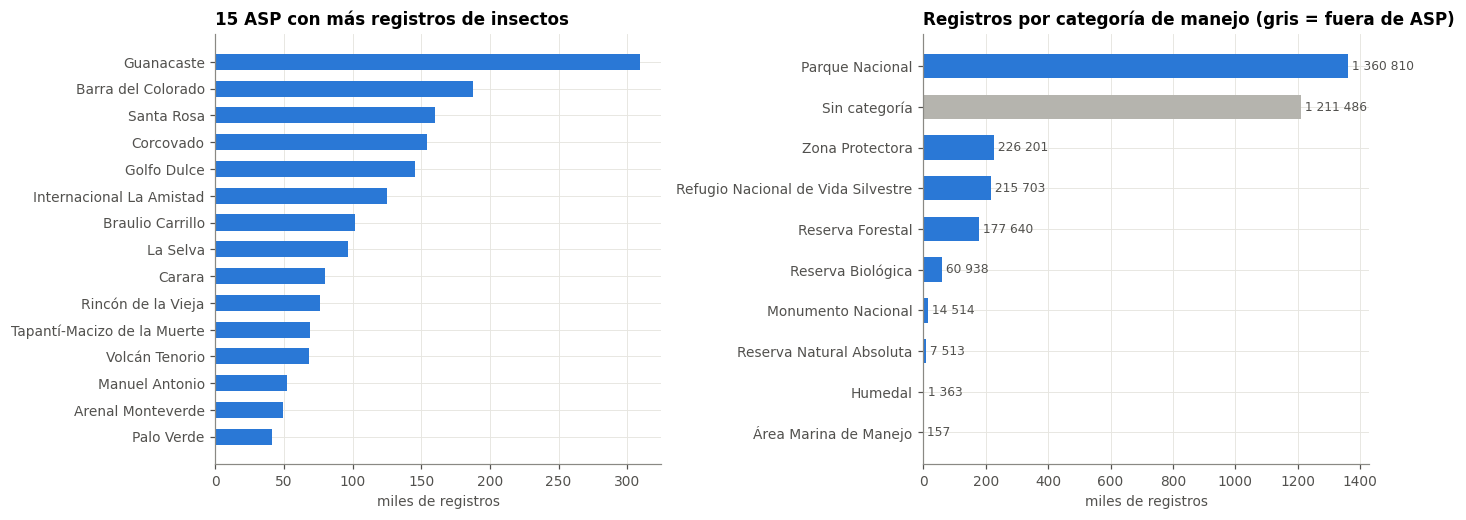

In [53]:
top = (integrado.where("dentro_asp").groupBy("area_protegida", "categoria_manejo").count().orderBy(F.desc("count")).limit(15).toPandas())
cat = integrado.groupBy("categoria_manejo").count().orderBy(F.desc("count")).toPandas()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.barh(top.area_protegida, top["count"] / 1e3, color=AZUL, height=0.6); a1.invert_yaxis()
a1.set_title("15 ASP con más registros de insectos"); a1.set_xlabel("miles de registros")
colores = [GRIS if c == "Sin categoría" else AZUL for c in cat.categoria_manejo]
a2.barh(cat.categoria_manejo, cat["count"] / 1e3, color=colores, height=0.6); a2.invert_yaxis()
for y_, v in enumerate(cat["count"]):
    a2.text(v / 1e3, y_, f" {miles(v)}", va="center", color=TINTA, fontsize=8)
a2.set_title("Registros por categoría de manejo (gris = fuera de ASP)"); a2.set_xlabel("miles de registros")
plt.tight_layout(); plt.show()

**Interpretación.** El **Parque Nacional Guanacaste** concentra la mayor cantidad de registros (309 464), seguido
de Barra del Colorado, Santa Rosa y Corcovado: corresponden a las áreas donde el INBio mantuvo estaciones
biológicas y programas de inventario de largo plazo. Por categoría, los **Parques Nacionales** reúnen 1 360 810
registros, más que todo lo recolectado fuera de las ASP (1 211 486). Siguen las Zonas Protectoras (226 201), los
Refugios de Vida Silvestre (215 703) y las Reservas Forestales (177 640). Los Humedales (1 363) y las Áreas Marinas
de Manejo (157) casi no tienen registros, como es de esperar en insectos terrestres.

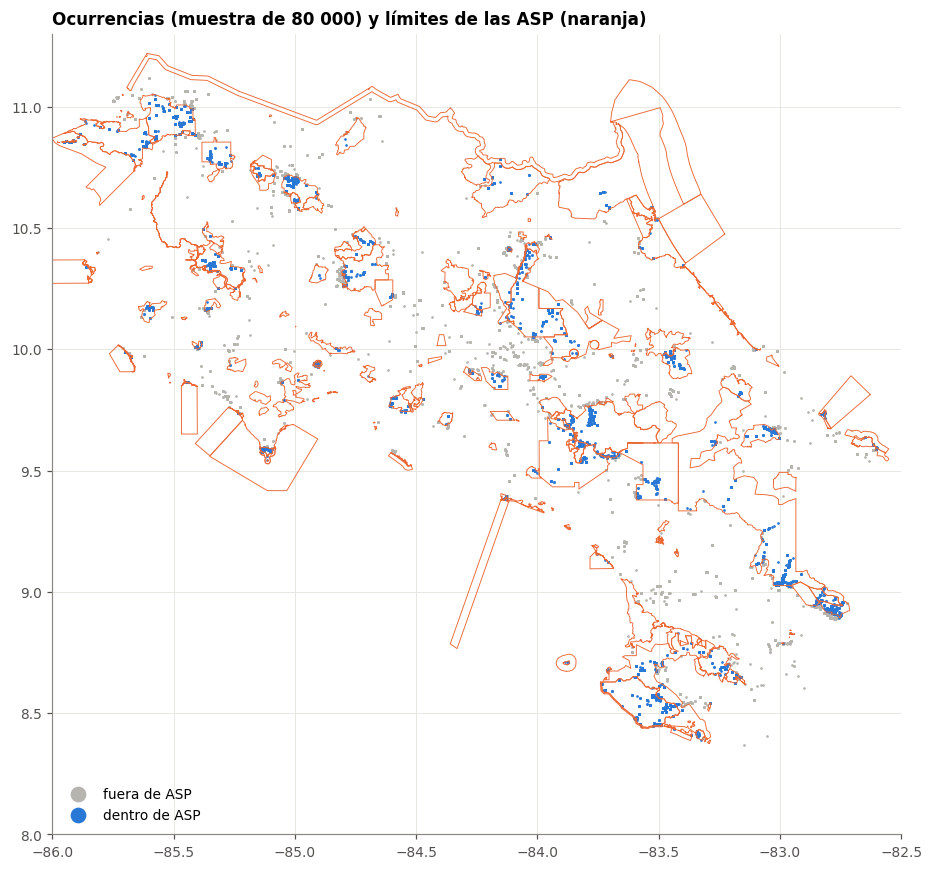

In [54]:
asp_pd = asp.select("area_protegida", "geom").toPandas()
mp = integrado.select("longitud", "latitud", "dentro_asp").sample(fraction=min(1.0, 80000 / N_DESPUES), seed=SEMILLA).toPandas()
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.scatter(mp.longitud[~mp.dentro_asp], mp.latitud[~mp.dentro_asp], s=0.6, c=GRIS, label="fuera de ASP", rasterized=True)
ax.scatter(mp.longitud[mp.dentro_asp], mp.latitud[mp.dentro_asp], s=0.6, c=AZUL, label="dentro de ASP", rasterized=True)
for g in asp_pd.geom:
    for poli in getattr(g, "geoms", [g]):
        if poli.geom_type == "Polygon":
            ax.plot(*poli.exterior.xy, color=NARANJA, lw=0.6)
ax.set_xlim(-86.0, -82.5); ax.set_ylim(8.0, 11.3); ax.set_aspect("equal")
ax.set_title("Ocurrencias (muestra de 80 000) y límites de las ASP (naranja)")
ax.legend(frameon=False, markerscale=12, loc="lower left"); plt.tight_layout(); plt.show()

**Interpretación.** Los puntos azules (dentro de ASP) siguen los contornos de los polígonos, lo que confirma
visualmente que la reproyección y el join espacial son correctos. Los puntos grises (fuera de ASP) se agrupan en
estaciones de muestreo cercanas a los límites de las áreas y en zonas agrícolas de tierras bajas. También se ven
ASP grandes con muy pocos registros (sectores de la Cordillera de Talamanca y del Caribe norte): son vacíos de
muestreo, no ausencia de insectos.

## 7. Preparación de los datos para Apache Solr

- **Atributos disponibles para consulta:** los del esquema definido en `solr/crear_esquema.py` (taxonomía, tiempo,
  lugar, ASP, colecta y variables derivadas). Las columnas de trabajo (fechas inicio/fin, celdas, banderas de
  imputación, distancia al borde) se quedan en el notebook.
- **Identificador único:** `id` = `occurrenceID` del INBio (URN `urn:catalog:INB:<colección>:<número>`), único y
  estable entre corridas; verificado en §2.4 y §6.4.
- **Tipos:** textos y categorías como `string`; numéricos `pint`/`pdouble`; `fecha_evento` en ISO 8601 UTC
  (`AAAA-MM-DDT00:00:00Z`, formato de `pdate`); `dentro_asp` booleano.
- **Coordenadas:** el campo `ubicacion` usa el formato `"lat,lon"` que espera el tipo espacial RPT de Solr
  (`SpatialRecursivePrefixTreeFieldType`), además de `latitud` y `longitud` numéricos.
- **Valores nulos:** se omiten del documento JSON (en Solr, campo ausente = sin valor).
- **Formato de salida:** JSON Lines comprimido con gzip, ordenado por `id` y particionado en archivos de como
  máximo 250 000 documentos (< 100 MB cada uno, límite de GitHub).

In [55]:
esquema_src = open(f"{RAIZ}/solr/crear_esquema.py", encoding="utf-8").read()
CAMPOS_SOLR = [c[0] for c in ast.literal_eval(esquema_src.split("CAMPOS = ", 1)[1].split("\n]\n", 1)[0] + "\n]")]
CAMPOS_EXPORTAR = ["id"] + [c for c in CAMPOS_SOLR if c not in ("texto", "nombre_cientifico_exacto")]
print("Campos del esquema Solr:", CAMPOS_EXPORTAR)

solr_df = (integrado
           .withColumn("fecha_evento", F.date_format("fecha_evento", "yyyy-MM-dd'T'00:00:00'Z'"))
           .withColumn("ubicacion", F.concat_ws(",", F.col("latitud").cast("string"), F.col("longitud").cast("string")))
           .withColumn("elevacion_m", F.round("elevacion_m", 1))
           .withColumn("area_protegida_km2", F.round("area_protegida_km2", 3))
           .withColumn("anio", F.col("anio").cast("int")).withColumn("mes", F.col("mes").cast("int"))
           .select(*CAMPOS_EXPORTAR))
faltan = set(CAMPOS_EXPORTAR) - set(solr_df.columns)
assert not faltan, faltan
solr_df.printSchema()
ver(solr_df, 3).T

Campos del esquema Solr: ['id', 'nombre_cientifico', 'orden', 'familia', 'genero', 'especie', 'rango_taxonomico', 'fecha_evento', 'anio', 'mes', 'estacion', 'provincia', 'canton', 'localidad', 'latitud', 'longitud', 'ubicacion', 'elevacion_m', 'piso_altitudinal', 'dentro_asp', 'area_protegida', 'categoria_manejo', 'area_conservacion', 'area_protegida_km2', 'etapa_vida', 'sexo', 'protocolo_muestreo', 'recolector']
root
 |-- id: string (nullable = true)
 |-- nombre_cientifico: string (nullable = true)
 |-- orden: string (nullable = true)
 |-- familia: string (nullable = true)
 |-- genero: string (nullable = true)
 |-- especie: string (nullable = true)
 |-- rango_taxonomico: string (nullable = true)
 |-- fecha_evento: string (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)
 |-- estacion: string (nullable = true)
 |-- provincia: string (nullable = true)
 |-- canton: string (nullable = true)
 |-- localidad: string (nullable = true)
 |-- latitud: dou

,0,1,2
id,urn:catalog:INB:Atta:1000001,urn:catalog:INB:Atta:1000037,urn:catalog:INB:Atta:1000040
nombre_cientifico,Homeomastax surda,Lygaeidae,Insecta
orden,Orthoptera,Hemiptera,No determinado
familia,Eumastacidae,Lygaeidae,No determinado
genero,Homeomastax,None,None
especie,Homeomastax surda,None,None
rango_taxonomico,Especie,Familia,Clase
fecha_evento,1989-04-01T00:00:00Z,1989-09-01T00:00:00Z,1986-02-06T00:00:00Z
anio,1989,1989,1986
mes,4,9,2


In [56]:
import shutil
SALIDA = f"{LIMPIOS}/insectos_asp"
t0 = time.time()
(solr_df.repartitionByRange(12, "id").sortWithinPartitions("id").write.mode("overwrite")
 .option("compression", "gzip").option("maxRecordsPerFile", 250_000)
 .json(SALIDA))
for f in glob.glob(f"{SALIDA}/.*.crc") + glob.glob(f"{SALIDA}/_SUCCESS"):
    os.remove(f)
archivos = sorted(glob.glob(f"{SALIDA}/part-*.json.gz"))
tam = pd.DataFrame({"archivo": [os.path.basename(a) for a in archivos], "MB": [round(os.path.getsize(a) / 1e6, 1) for a in archivos]})
print(f"Escritura: {time.time() - t0:.0f} s | {len(archivos)} archivos | {tam.MB.sum():.0f} MB en total | máximo {tam.MB.max()} MB")
assert tam.MB.max() < 100, "Algún archivo supera 100 MB"

Escritura: 8 s | 23 archivos | 61 MB en total | máximo 5.5 MB


**Verificación de la salida:** se vuelve a leer lo escrito con Spark y se comprueba conteo, unicidad de `id`,
coordenadas y formato de `ubicacion`.

In [57]:
final = spark.read.json(SALIDA)
N_FINAL = final.count()
verif = final.agg(
    F.countDistinct("id").alias("ids_distintos"),
    F.sum(F.when(F.col("ubicacion").rlike(r"^-?\d+(\.\d+)?,-?\d+(\.\d+)?$"), 1).otherwise(0)).alias("ubicacion_bien_formada"),
    F.sum(F.col("dentro_asp").cast("int")).alias("dentro_asp"),
    F.min("fecha_evento").alias("fecha_min"), F.max("fecha_evento").alias("fecha_max")).toPandas()
print("Documentos escritos:", miles(N_FINAL)); display(verif)
assert N_FINAL == N_DESPUES == verif.ids_distintos[0] == verif.ubicacion_bien_formada[0]
registrar("6. Documentos para Solr", final)

resumen_etl = {
    "registros_crudos_gbif": N_GBIF, "poligonos_asp": N_ASP, "documentos_solr": N_FINAL,
    "dentro_asp": int(verif.dentro_asp[0]), "fuera_asp": N_FINAL - int(verif.dentro_asp[0]),
    "archivos": len(archivos), "mb_total": round(float(tam.MB.sum()), 1),
    "bitacora": bitacora, "generado": time.strftime("%Y-%m-%d %H:%M:%S"),
}
with open(f"{LIMPIOS}/resumen_etl.json", "w", encoding="utf-8") as fh:
    json.dump(resumen_etl, fh, ensure_ascii=False, indent=2)
pd.DataFrame(bitacora)

Documentos escritos: 3 276 325


,ids_distintos,ubicacion_bien_formada,dentro_asp,fecha_min,fecha_max
0,3276325,3276325,2064839,1941-05-11T00:00:00Z,2015-11-05T00:00:00Z


6. Documentos para Solr: 3 276 325


,paso,registros
0,0. Datos crudos GBIF,3276500
1,1. Sin duplicados por id,3276500
2,2. Limpio (antes de tratar faltantes),3276500
3,3. Sin registros con coordenadas faltantes o inválidas,3276325
4,4. Después de imputación,3276325
5,5. Integrado con ASP (left join),3276325
6,6. Documentos para Solr,3276325


## 8. Conclusiones

**Calidad de los datos.** La colección del INBio es grande y bien georreferenciada: de 3 276 500 especímenes solo
175 carecían de coordenadas y ninguno cayó fuera de Costa Rica, no hay identificadores duplicados y solo 2 fechas
eran imposibles. Sus problemas son de **completitud y codificación**, no de errores: el sexo falta en el 78 %, el
protocolo en el 62 %, el 17,9 % de los especímenes no está identificado más allá de clase o reino, y los faltantes
se esconden tras textos como «Desconocido». La capa del SINAC, en cambio, tiene problemas de **identidad**: el
código del ASP no es único y cambia entre versiones, por lo que hubo que crear un identificador propio.

**Patrones encontrados.** El 63,0 % de las ocurrencias (2 064 839) se registró dentro de un ASP, aunque las ASP
cubren alrededor de una cuarta parte del territorio continental: el esfuerzo de inventario del INBio se concentró
en las áreas protegidas, en especial los Parques Nacionales (1,36 M registros) y las áreas de Guanacaste, Santa
Rosa, Corcovado y La Amistad. La recolecta está sesgada a tierras bajas (el piso Basal tiene la mitad de los
registros) y al periodo 1990–2000. Coleoptera, Lepidoptera, Diptera e Hymenoptera dominan la colección.

**Relaciones entre variables.** La elevación depende fuertemente de la ubicación (una mediana de 1 km la predice
con ≈12 m de error), lo que justificó la imputación espacial y explica por qué los algoritmos multivariados
detectan sobre todo incoherencias de ubicación–elevación. La etapa de vida está casi determinada por el método de
recolecta (adultos en trampas).

**Utilidad del pipeline ETL.** Todo el procesamiento (lectura, limpieza, imputación, join espacial con Sedona,
escritura) corre en Spark en ≈6 minutos sobre una sola máquina y es reproducible de punta a punta: descarga con
`etl/descargar_datos.py`, ejecución del notebook en el contenedor `spark` y carga con `solr/indexar.py`. La bitácora
muestra que los únicos registros eliminados fueron los 175 sin coordenadas, y las aserciones garantizan que el join
no pierde ni duplica registros. El resultado son 3 276 325 documentos (muy por encima de los 100 000 exigidos) en
23 archivos JSON Lines comprimidos (61 MB).

**Detección de anomalías.** Los tres algoritmos coinciden poco porque responden a definiciones distintas de
«anómalo»; la mayoría de lo detectado son hábitats reales y poco muestreados (alta montaña, Isla del Coco, años
extremos del inventario), por lo que los registros se conservan. LOF es el más útil para revisar errores de
georreferenciación y Isolation Forest el más práctico a escala completa; IQR solo es adecuado como filtro de rango.

**Limitaciones.** (1) El join usa la capa 2023 del SINAC; dos cambios de 2025 no tienen polígono. (2) Las
coordenadas del INBio corresponden a la estación o trampa, no al punto exacto del especímen, por lo que los
registros a pocos metros del límite (25 % a menos de 291 m) podrían asignarse a un lado u otro del borde. (3) La
fecha del evento es el inicio del periodo de muestreo (mediana de 25 días). (4) LOF se aplicó a una muestra
estratificada y el umbral de Isolation Forest es una decisión del análisis. (5) La abundancia de registros refleja
el esfuerzo de muestreo, no la abundancia real de insectos.

## 9. Referencias

- INBio (2015). *Insecta of Costa Rica (INBio)*. Instituto Nacional de Biodiversidad. Occurrence dataset
  publicado vía GBIF.org, `3e9817c1-8302-4955-87e3-a408db0ea379`.
  <https://www.gbif.org/dataset/3e9817c1-8302-4955-87e3-a408db0ea379> (licencia CC0 1.0).
- SINAC (2023). *Límites de las Áreas Silvestres Protegidas de Costa Rica, versión 2023* (shapefile, CRTM05).
  Sistema Nacional de Áreas de Conservación. <https://www.sinac.go.cr/ES/asp/Paginas/default.aspx>
- SINAC (2025). *Áreas Silvestres Protegidas de Costa Rica, versión 2025* (registro oficial, .xls).
  <https://www.sinac.go.cr/ES/asp/Paginas/default.aspx>
- Wieczorek, J. et al. (2012). Darwin Core: An Evolving Community-Developed Biodiversity Data Standard.
  *PLoS ONE* 7(1): e29715.
- Apache Software Foundation. *Apache Spark 3.5 documentation*. <https://spark.apache.org/docs/3.5.0/>
- Apache Software Foundation. *Apache Sedona documentation — Spatial SQL*. <https://sedona.apache.org/>
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley. (método IQR)
- Liu, F. T., Ting, K. M. y Zhou, Z.-H. (2008). Isolation Forest. *IEEE ICDM*, 413–422.
- Breunig, M. M., Kriegel, H.-P., Ng, R. T. y Sander, J. (2000). LOF: Identifying Density-Based Local Outliers.
  *ACM SIGMOD*, 93–104.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825–2830.
- Holdridge, L. R. (1967). *Life Zone Ecology*. Tropical Science Center, San José, Costa Rica.